# Data Engineering & Visualization – Milestone 1
**Housing & Development × Transportation in New York City**

**Team:** complete the team's actual member names and IDs before submission.
**Course:** Data Engineering and Visualization, Winter 2026 – GIU

## Notebook outline
1. Research focus
2. Datasets and selection reasoning
3. Exploratory data analysis (EDA)
4. Scope decisions
5. Pre-integration cleaning
6. Integration
7. Post-integration cleaning
8. Contributions and prompts used

**Self-contained execution:** every processing function is written in this notebook's visible code cells. No accompanying Python scripts, previous integrated files or earlier project ZIP are needed. Input files are data only. Run every cell from the top.

**Two geography alternatives:** the two notebooks have identical cell sources except for `USE_BOUNDARY_REFERENCE` below. With it enabled, missing districts can be recovered through the official boundary lookup and conflicting evidence is quarantined. With it disabled, only valid, borough-consistent reported districts are used; records without usable codes remain in full detail/audits and are omitted from district-level totals. Coordinates, ZIP codes and precincts are not used to guess missing districts in that mode.

**Task scope:** the original data-preparation, audits and diagnostic figures are preserved; Section 7.4 now answers two new research questions using one simple chart.

## 1. Research questions

1. Do new-housing completions and serious crashes peak in the same month?
2. Does the gap between those peaks differ across boroughs?

Both are answered by one chart in Section 7.4.


## 2. Datasets and selection reasoning

| Domain | Dataset | ID | Source |
|---|---|---|---|
| Housing & Development (H2) | Affordable Housing Production by Building | hg8x-zxpr | https://data.cityofnewyork.us/d/hg8x-zxpr |
| Transportation (T4) | Serious Injury Response, Tracking & Analysis Program | xeqp-qz8h | https://data.cityofnewyork.us/d/xeqp-qz8h |

Housing provides project/building counts, construction categories, completion dates and geography. SIRTA provides event dates/times, reported harm, lookbacks and geography. All original columns are retained so later questions about bedroom/income/tenure mix remain possible.

**Optional supporting reference:** official DCP Community District polygons (`5crt-au7u`) are used only when the mode flag is true. They are a geographic lookup, not another analytical housing/transportation source. The current reference can differ from historical source geocoding; hashes record exactly which file was used.

**Inputs:** put the original source files named `housing.csv` and `transport.csv` in an `inputs/` folder if you want to use frozen snapshots. The boundary-enabled version also accepts `inputs/community_districts_26b.geojson`. Otherwise the notebook downloads the complete files from the public sources. On subsequent runs it reuses its cached inputs. A source schema change causes an explicit validation failure rather than silent adaptation.

**Outputs:** each mode writes to a separate folder and creates a downloadable results ZIP at the end. No external processing-code file is imported.

In [1]:
# THIS BOOLEAN IS THE ONLY CELL-SOURCE DIFFERENCE BETWEEN THE TWO NOTEBOOKS.
USE_BOUNDARY_REFERENCE = True

from pathlib import Path
import collections, csv, datetime, decimal, gzip, hashlib, html, io, json, math
import re, shutil, sqlite3, statistics, sys, urllib.request, zipfile
from urllib.error import HTTPError, URLError

MODE_NAME = "with_boundaries" if USE_BOUNDARY_REFERENCE else "reported_codes_only"
OUTPUT_ROOT = Path.cwd() / ("DEV_" + MODE_NAME)
INPUT_DIR = Path.cwd() / "inputs"
SOURCE_URLS = {
    "housing.csv": "https://data.cityofnewyork.us/api/views/hg8x-zxpr/rows.csv?accessType=DOWNLOAD",
    "transport.csv": "https://data.cityofnewyork.us/api/views/xeqp-qz8h/rows.csv?accessType=DOWNLOAD",
}
BOUNDARY_URL = "https://data.cityofnewyork.us/api/geospatial/5crt-au7u?method=export&format=GeoJSON"
print("Geography mode:", MODE_NAME)
print("Output folder:", OUTPUT_ROOT.name)

Geography mode: with_boundaries
Output folder: DEV_with_boundaries


### Execution plan before transformations
1. Freeze inputs and their hashes; inspect every original column and cell.
2. Parse types, normalize formats, distinguish nulls from validated component zeros, and audit identities/counts/dates/categories.
3. Apply the selected geography policy without inventing district assignments.
4. Preserve all source rows in full cleaned detail; define explicit eligibility for New Construction completions and SIRTA events, 2022-2025.
5. Aggregate sources independently to district/year, then join one-to-one. Preserve hourly and wider program-activity summaries separately.
6. Perform post-integration checks and independent export verification; retain all exceptions and alternative assumptions.
7. Export the final data, dictionaries, diagnostic charts, audit ledger and results ZIP. Leave individual question answers and website deliverables for the next project stage.

In [2]:
# Download data only when no local snapshot is available. No code is fetched or executed.
def obtain_input(destination, candidates, url):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists():
        print("Using cached input:", destination.name)
        return destination
    for candidate in candidates:
        candidate = Path(candidate)
        if candidate.is_file():
            shutil.copyfile(candidate, destination)
            print("Using supplied input:", candidate.name)
            return destination
    print("Downloading complete source:", destination.name)
    temporary = destination.with_suffix(destination.suffix + ".download")
    try:
        with urllib.request.urlopen(url, timeout=90) as response, temporary.open("wb") as target:
            shutil.copyfileobj(response, target)
        temporary.replace(destination)
    except (HTTPError, URLError) as e:
        print(f"\n[WARNING] Failed to download {destination.name} due to network/server issue: {e}")
        print("Please manually upload the frozen snapshot to the 'inputs/' folder in your Colab files tab to bypass this.")
        if temporary.exists():
            temporary.unlink()
        raise e
    finally:
        if temporary.exists():
            temporary.unlink()
    return destination

try:
    for filename, url in SOURCE_URLS.items():
        obtain_input(OUTPUT_ROOT / "raw" / filename,
                     [INPUT_DIR / filename, Path.cwd() / "raw" / filename,
                      Path.cwd() / "DEV_Cleaning_Integration" / "raw" / filename], url)

    if USE_BOUNDARY_REFERENCE:
        obtain_input(OUTPUT_ROOT / "reference" / "community_districts_26b.geojson",
                     [INPUT_DIR / "community_districts_26b.geojson",
                      Path.cwd() / "reference" / "community_districts_26b.geojson",
                      Path.cwd() / "DEV_Cleaning_Integration" / "reference" / "community_districts_26b.geojson"],
                     BOUNDARY_URL)
    else:
        print("Boundary files are not loaded, downloaded or consulted in this mode.")
except Exception as e:
    print("\nExecution halted. Setup the 'inputs/' directory with raw CSVs to run offline.")

In [3]:
BORO={1:'Manhattan',2:'Bronx',3:'Brooklyn',4:'Queens',5:'Staten Island'}
BORONUM={v:k for k,v in BORO.items()}
PREFIX={'MN':1,'BX':2,'BK':3,'QN':4,'SI':5}
INCOME=['Extremely Low Income Units','Very Low Income Units','Low Income Units','Moderate Income Units','Middle Income Units','Other Income Units']
BEDROOM=['Studio Units','1-BR Units','2-BR Units','3-BR Units','4-BR Units','5-BR Units','6-BR+ Units','Unknown-BR Units']
TENURE=['Counted Rental Units','Counted Homeownership Units']
UNITS=INCOME+BEDROOM+TENURE+['All Counted Units','Total Units']
UNITKEY=dict(zip(UNITS,['extremely_low_income_units','very_low_income_units','low_income_units','moderate_income_units','middle_income_units','other_income_units','studio_units','one_br_units','two_br_units','three_br_units','four_br_units','five_br_units','six_plus_br_units','unknown_br_units','rental_units','homeownership_units','affordable_units','total_units']))
LOOK='Similar Fatalities & Severe Injuries (3Y Lookback)'
LOOKALL='Similar Fatalities & All Injuries (3Y Lookback)'
COUNTS=['Total Non-Severe Injuries','Total Severe Injuries','Total Fatalities',LOOK,LOOKALL]
HIDS={'Project ID','Building ID','Postcode','BBL','BIN','Council District','Census Tract'}
TIDS={'Collision ID','Crash Police Precinct','ZipCode','Community Board','Council District','Building Identification Number (BIN)','Borough Block Lot (BBL)','Census Tract (2020)'}
COORDS={'Latitude','Longitude','Latitude (Internal)','Longitude (Internal)'}
START,END=2022,2025

MAX_DISTRICT = {1:12, 2:12, 3:18, 4:14, 5:3}
REGULAR = {100 * borough + district for borough, maximum in MAX_DISTRICT.items()
           for district in range(1, maximum + 1)}
def sha(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def slug(text):return re.sub('[^a-z0-9]+','_',text.lower()).strip('_')

def write_json(path,value):
    Path(path).parent.mkdir(parents=True,exist_ok=True)
    Path(path).write_text(json.dumps(value,ensure_ascii=False,indent=2,allow_nan=False)+'\n',encoding='utf-8')

def read_csv(path):
    with Path(path).open(encoding='utf-8-sig',newline='') as f:
        reader=csv.DictReader(f);rows=list(reader);fields=reader.fieldnames
    assert fields and len(fields)==len(set(fields))
    assert all(None not in r and all(v is not None for v in r.values()) for r in rows),'Malformed CSV row width'
    return rows,fields

def write_csv(path,rows,fields=None):
    rows=list(rows)
    if fields is None:
        fields=list(dict.fromkeys(k for r in rows for k in r))
    Path(path).parent.mkdir(parents=True,exist_ok=True)
    with Path(path).open('w',encoding='utf-8',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=fields,extrasaction='raise');writer.writeheader()
        for r in rows:writer.writerow({k:('' if r.get(k) is None else int(r[k]) if isinstance(r.get(k),bool) else r.get(k,'')) for k in fields})

def number(text):
    try:
        d=decimal.Decimal(str(text))
        if not d.is_finite():return None
        return int(d) if d==d.to_integral_value() else float(d)
    except (decimal.InvalidOperation,TypeError,ValueError):return None

def integer(text):
    n=number(text)
    return n if isinstance(n,int) else None

def as_date(text):
    if not text:return None
    try:return datetime.datetime.strptime(text,'%m/%d/%Y').date().isoformat()
    except ValueError:return None

def year(iso):return int(iso[:4]) if iso else None

def time_value(text):
    m=re.fullmatch(r'(\d{1,2}):(\d{2})',text)
    if not m:return None
    h,mn=map(int,m.groups())
    return f'{h:02d}:{mn:02d}' if 0<=h<=23 and 0<=mn<=59 else None

def coordinate_pair(row,internal=False):
    lat=row.get('Latitude (Internal)' if internal else 'Latitude')
    lon=row.get('Longitude (Internal)' if internal else 'Longitude')
    if lat is None or lon is None:return None,None
    if not -90<=lat<=90 or not -180<=lon<=180 or (lat==0 and lon==0):return None,None
    return lon,lat

def percentile(values,p):
    a=sorted(values)
    if not a:return None
    pos=(len(a)-1)*p;lo=int(pos);hi=min(lo+1,len(a)-1)
    return a[lo]+(a[hi]-a[lo])*(pos-lo)

## 3. Exploratory data analysis (EDA)
### 3.1 Size and structure
Read the entire source files, validate the expected 41 and 23 columns, and profile every source cell. Identifiers remain exact text. The first-record previews below do not substitute for the full inspection.

The following class stores data, audits and checks only; it contains no hidden imported processing code.

In [4]:
import collections

class Context:
    def __init__(self,root):
        self.root=Path(root).resolve();self.audit=[];self.cells=[];self.profiles=[];self.value_counts=[];self.stats={};self.tests=[]
        self.raw={};self.fields={};self.cleaned={};self.cd_audit=[];self.source_manifest=[];self.outlier_thresholds=[]
        self.locator=None
        for d in ['data','audits','charts','docs']: (self.root/d).mkdir(exist_ok=True)
    def issue(self,dataset,row,column,code,detail,severity='review'):
        self.audit.append(dict(dataset=dataset,source_row=row,column=column,code=code,severity=severity,detail=detail))
    def check(self,name,condition,detail=''):
        self.tests.append(dict(check=name,passed=bool(condition),detail=str(detail)))
        if not condition:raise AssertionError(name+': '+str(detail))

def inspect_sources(ctx):
    """Read every cell. Capture distinct distributions for every original column."""
    for name,expected in [('housing',41),('transport',23)]:
        path=ctx.root/'raw'/f'{name}.csv'
        rows,fields=read_csv(path);ctx.raw[name]=rows;ctx.fields[name]=fields
        ctx.check(name+'_column_count',len(fields)==expected)
        ctx.source_manifest.append({'file':path.relative_to(ctx.root).as_posix(),'sha256':sha(path),'rows':len(rows),'columns':len(fields),'cells':len(rows)*len(fields)})
        for col in fields:
            vals=[r[col] for r in rows];non=[v.strip() for v in vals if v.strip()]
            counter=collections.Counter(non);nums=[number(x) for x in non];numeric=[x for x in nums if x is not None]
            dates=[as_date(x) for x in non] if 'Date' in col else []
            ctx.profiles.append(dict(dataset=name,column=col,rows=len(rows),blank=sum(not x.strip() for x in vals),
                distinct_nonblank=len(counter),whitespace_changes=sum(x!=x.strip() for x in vals),
                numeric_parseable=len(numeric),numeric_min=min(numeric) if numeric else None,numeric_max=max(numeric) if numeric else None,
                date_parse_failures=sum(x is None for x in dates),date_min=min((x for x in dates if x),default=None),date_max=max((x for x in dates if x),default=None),top_values=json.dumps(counter.most_common(8),ensure_ascii=False)))
            for val,count in sorted(counter.items()):ctx.value_counts.append(dict(dataset=name,column=col,value=val,count=count))
    write_csv(ctx.root/'audits/column_profiles.csv',ctx.profiles)
    write_csv(ctx.root/'audits/all_distinct_values.csv',ctx.value_counts)
    ctx.stats['source_rows']={n:len(r) for n,r in ctx.raw.items()}
    ctx.stats['source_cells']=sum(len(ctx.raw[n])*len(ctx.fields[n]) for n in ctx.raw)
    return ctx

ctx = Context(OUTPUT_ROOT)
inspect_sources(ctx)
print("Rows:", ctx.stats["source_rows"])
print("Source cells inspected:", ctx.stats["source_cells"])

Rows: {'housing': 9551, 'transport': 13754}
Source cells inspected: 707933


In [5]:
def table_html(records,columns=None,limit=100):
    records=list(records)
    if not records:return '<p>No records.</p>'
    columns=columns or list(records[0])
    head=''.join('<th>'+html.escape(str(c))+'</th>' for c in columns)
    body=''.join('<tr>'+''.join('<td>'+html.escape('' if r.get(c) is None else str(r.get(c,'')))+'</td>' for c in columns)+'</tr>' for r in records[:limit])
    return '<div style="overflow:auto"><table><thead><tr>'+head+'</tr></thead><tbody>'+body+'</tbody></table></div>'

def show_table(records, columns=None, limit=100):
    display({"text/html": table_html(records, columns, limit)}, raw=True)

show_table(ctx.source_manifest)

file,sha256,rows,columns,cells
raw/housing.csv,a6f48edd49140c86095725869bef016489b32f574522fc0d75b2e2bb18fbfd9f,9551,41,391591
raw/transport.csv,d5f7c1c47b7ff1832d3b66632f75578db951bdb8667dfb48467cd756c249036d,13754,23,316342


### 3.2 First look at the records
These are raw inputs. Raw evidence will remain unchanged and can be traced through `source_key` and physical CSV row number.

In [6]:
print("HOUSING DATASET")
show_table(ctx.raw["housing"], limit=5)
print("SIRTA DATASET")
show_table(ctx.raw["transport"], limit=5)

HOUSING DATASET


Project ID,Project Name,Project Start Date,Project Completion Date,Building ID,Number,Street,Borough,Postcode,BBL,BIN,Community Board,Council District,Census Tract,NTA - Neighborhood Tabulation Area,Latitude,Longitude,Latitude (Internal),Longitude (Internal),Building Completion Date,Reporting Construction Type,Extended Affordability Only,Prevailing Wage Status,Extremely Low Income Units,Very Low Income Units,Low Income Units,Moderate Income Units,Middle Income Units,Other Income Units,Studio Units,1-BR Units,2-BR Units,3-BR Units,4-BR Units,5-BR Units,6-BR+ Units,Unknown-BR Units,Counted Rental Units,Counted Homeownership Units,All Counted Units,Total Units
68872,177-06 WEXFORD TERRACE,06/30/2026,,991637,177-06,WEXFORD TERRACE,Queens,11432,4098350023,4000000,QN-08,24,466,QN06,40.713096,-73.786005,40.712656,-73.786724,,New Construction,No,Non Prevailing Wage,,,9,,,,,9,,,,,,,9,,9,43
72436,ST. NICK'S. 819 GRAND STREET,06/30/2026,,1021347,819,GRAND STREET,Brooklyn,11211,3029220001,3070436,BK-01,34,481,BK90,40.71205,-73.94036,40.712272,-73.940295,,New Construction,No,Prevailing Wage,186,,,,,1,92,95,,,,,,,187,,187,187
72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,,21199,127,EDGECOMBE AVENUE,Manhattan,10030,1020480037,1060911,MN-10,9,22102,MN03,40.820728,-73.945285,40.820766,-73.945581,,Preservation,No,Non Prevailing Wage,12,13,,,,,,5,20,,,,,,25,,25,25
72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,,28145,602,ST NICHOLAS AVENUE,Manhattan,10030,1020480047,1060920,MN-10,9,22102,MN03,40.820717,-73.946322,40.820591,-73.946058,,Preservation,No,Non Prevailing Wage,6,9,,,,1,1,10,5,,,,,,16,,16,16
72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,,40555,129,WEST 133 STREET,Manhattan,10030,1019180018,1058219,MN-10,9,226,MN03,40.813338,-73.943026,40.813568,-73.943011,,Preservation,No,Non Prevailing Wage,5,10,,,,,1,4,6,4,,,,,15,,15,15


SIRTA DATASET


Collision ID,Crash Date,Crash Time,Crash Police Precinct,Crash Borough,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities,Latitude,Longitude,On Street,Cross Street,Address,Highway Reference Marker,ZipCode,Similar Fatalities & Severe Injuries (3Y Lookback),Similar Fatalities & All Injuries (3Y Lookback),Community Board,Council District,Building Identification Number (BIN),Borough Block Lot (BBL),Census Tract (2020),Neighborhood Tabulation Area (NTA) (2020)
4492364,01/01/2022,01:28,46,Bronx,1,1,0,40.858707,-73.9037,JEROME AVENUE,EAST 183 STREET,,,,0,1,,,,,,
4491159,01/01/2022,04:33,46,Bronx,0,1,0,,,JEROME AVENUE,,,,,0,0,,,,,,
4491487,01/01/2022,05:55,47,Bronx,0,1,0,40.87155,-73.86428,,,3207 WALLACE AVENUE,,,0,0,212,12,2056281,2045980025,372,BX1201
4491223,01/01/2022,10:42,43,Bronx,0,1,0,40.823673,-73.87233,BRONX RIVER PARKWAY,,,907HX1M11001,,0,0,,,,,,
4491418,01/01/2022,20:55,49,Bronx,0,1,0,40.863945,-73.86452,BOSTON ROAD,WALLACE AVENUE,,,,0,0,,,,,,


### 3.3 Columns, data types and missing values
The profile covers every source field, including complete nonblank value distributions exported to the audit. Missing remains unknown unless a specific component-family rule is proven. Income/bedroom categories describe units, not actual residents or crash victims.

In [7]:
show_table(ctx.profiles,
    columns=["dataset", "column", "rows", "blank", "distinct_nonblank", "numeric_parseable",
             "numeric_min", "numeric_max", "date_parse_failures", "date_min", "date_max"], limit=100)

dataset,column,rows,blank,distinct_nonblank,numeric_parseable,numeric_min,numeric_max,date_parse_failures,date_min,date_max
housing,Project ID,9551,0,5928,9551,44218,82249,0,,
housing,Project Name,9551,0,3979,0,,,0,,
housing,Project Start Date,9551,0,2346,0,,,0,2014-01-03,2026-06-30
housing,Project Completion Date,9551,1819,2066,0,,,0,2014-01-03,2026-08-11
housing,Building ID,9551,1949,7478,7602,375,1022537,0,,
housing,Number,9551,0,3154,6821,1,13110,0,,
housing,Street,9551,0,1567,0,,,0,,
housing,Borough,9551,0,5,0,,,0,,
housing,Postcode,9551,1958,158,7593,10001,11694,0,,
housing,BBL,9551,2021,6423,7530,1000050010,5080477501,0,,


### 3.4 Construction types and time coverage
Check source categories and date ranges before selecting the main period. Full cleaned detail will retain preservation, incomplete and out-of-period housing records for future analyses.

In [8]:
print("Construction types:", dict(collections.Counter(r["Reporting Construction Type"] for r in ctx.raw["housing"])))
print("Extended-affordability labels:", dict(collections.Counter(r["Extended Affordability Only"] for r in ctx.raw["housing"])))
show_table([r for r in ctx.profiles if "Date" in r["column"]],
           columns=["dataset", "column", "blank", "date_parse_failures", "date_min", "date_max"])

Construction types: {'New Construction': 4766, 'Preservation': 4785}
Extended-affordability labels: {'No': 8125, 'Yes': 1426}


dataset,column,blank,date_parse_failures,date_min,date_max
housing,Project Start Date,0,0,2014-01-03,2026-06-30
housing,Project Completion Date,1819,0,2014-01-03,2026-08-11
housing,Building Completion Date,1666,0,2014-01-03,2026-08-21
transport,Crash Date,444,0,2022-01-01,2026-06-30


### 3.5 Can the two datasets share a neighborhood label?
Housing NTA/census fields use older geography; SIRTA explicitly uses 2020 fields. They are retained but not directly equated. Community District is the shared administrative key.

**Boundary-enabled policy:** validate reported district/borough and both coordinate pairs where available. Recover missing crash districts only from a unique polygon match consistent with a known borough. Contradictory evidence, boundary ambiguity and special areas remain outside strict primary totals. No nearest-district guess is used.

**Reported-code-only policy:** normalize housing codes such as QN-08 to 408, validate regular district ranges and source borough agreement, and use those reported codes only. No coordinates, postal code, precinct, NTA or another record are used to infer a missing district. Missing/nonregular/disputed codes remain in the cleaned detail and exclusion audits, not in district totals. This sacrifices coverage transparently; it does not claim the missing events did not occur.

The polygon implementation is visible below in both files for source parity, but the reported-code-only mode never loads a boundary file or calls the locator. Synthetic mathematical tests need no boundary data.

In [ ]:
def ring_relation(x,y,ring,method='ray'):
    """Return -1 outside, 0 on boundary, 1 inside a closed ring."""
    inside=False;winding=0
    for a,b in zip(ring,ring[1:]):
        ax,ay=a[:2];bx,by=b[:2]
        cross=(bx-ax)*(y-ay)-(by-ay)*(x-ax)
        if abs(cross)<=1e-12 and min(ax,bx)-1e-10<=x<=max(ax,bx)+1e-10 and min(ay,by)-1e-10<=y<=max(ay,by)+1e-10:
            return 0
        if method=='ray':
            if (ay>y)!=(by>y) and x < ax+(y-ay)*(bx-ax)/(by-ay):inside=not inside
        else:
            if ay<=y<by and cross>0:winding+=1
            elif by<=y<ay and cross<0:winding-=1
    return 1 if (inside if method=='ray' else winding!=0) else -1

def polygon_relation(x,y,rings,method='ray'):
    outer=ring_relation(x,y,rings[0],method)
    if outer!=1:return outer
    for hole in rings[1:]:
        rel=ring_relation(x,y,hole,method)
        if rel==0:return 0
        if rel==1:return -1
    return 1

class DistrictLocator:
    def __init__(self,path):
        data=json.loads(Path(path).read_text(encoding='utf-8'))
        self.parts=[];self.features=data['features'];self.cache={}
        codes=set()
        for f in self.features:
            code=int(f['properties']['boro_cd']);codes.add(code)
            geom=f['geometry'];polys=geom['coordinates']
            if geom['type']=='Polygon':polys=[polys]
            assert geom['type'] in ['Polygon','MultiPolygon']
            for rings in polys:
                assert all(len(r)>=4 and r[0]==r[-1] for r in rings)
                points=rings[0];xs=[p[0] for p in points];ys=[p[1] for p in points]
                box=(min(xs),min(ys),max(xs),max(ys))
                assert -180<=box[0]<=box[2]<=180 and -90<=box[1]<=box[3]<=90
                self.parts.append((code,box,rings))
        assert REGULAR<=codes
        self.codes=codes

    def locate(self,lon,lat):
        if lon is None or lat is None:return (),()
        key=(lon,lat)
        if key in self.cache:return self.cache[key]
        inside=set();touches=set()
        for code,(xmin,ymin,xmax,ymax),rings in self.parts:
            if xmin-1e-10<=lon<=xmax+1e-10 and ymin-1e-10<=lat<=ymax+1e-10:
                rel=polygon_relation(lon,lat,rings,'ray')
                # Independent winding algorithm verifies every candidate result.
                other=polygon_relation(lon,lat,rings,'winding')
                if rel!=other:raise AssertionError(('polygon algorithm disagreement',key,code,rel,other))
                if rel==1:inside.add(code)
                elif rel==0:touches.add(code)
        result=(tuple(sorted(inside)),tuple(sorted(touches)))
        self.cache[key]=result
        return result

def self_test():
    square=[[0,0],[10,0],[10,10],[0,10],[0,0]]
    hole=[[3,3],[7,3],[7,7],[3,7],[3,3]]
    for method in ['ray','winding']:
        assert polygon_relation(1,1,[square,hole],method)==1
        assert polygon_relation(5,5,[square,hole],method)==-1
        assert polygon_relation(0,5,[square,hole],method)==0
        assert polygon_relation(3,5,[square,hole],method)==0
        assert polygon_relation(11,1,[square,hole],method)==-1
        assert polygon_relation(10,10,[square,hole],method)==0
        assert polygon_relation(1,1,[list(reversed(square)),list(reversed(hole))],method)==1
    return True

if USE_BOUNDARY_REFERENCE:
    ctx.locator = DistrictLocator(OUTPUT_ROOT / "reference" / "community_districts_26b.geojson")
    print("Reference features:", len(ctx.locator.features), "| regular districts:", len(REGULAR))
else:
    assert ctx.locator is None
    print("Using only the", len(REGULAR), "regular district-code definitions, with no boundary file.")

Reference features: 71 | regular districts: 59


## 4. Scope decisions
1. **Main housing branch:** New Construction completed during 2022-2025, matching the original notebook. All other records remain in full cleaned detail.
2. **Main crash branch:** identifiable, nonconflicting SIRTA events during 2022-2025 with usable outcomes and an acceptable district under the chosen mode.
3. **Dates:** preserve source administrative timing discrepancies. Completion does not mean occupancy; administrative project start is not necessarily physical construction start.
4. **Counts:** preserve affordable and total units separately and all category counts/known-value denominators. Do not replace unknown totals with zero.
5. **Housing identity:** apply the provisional earliest completed New Construction record per known Building ID across available history, with an all-project-record sensitivity. Missing IDs cannot be deduplicated by identity. Earliest-date ties are held for review.
6. **Geography:** the mode flag is the sole policy difference; all other cleaning and inclusion rules are shared.
7. **Future questions:** retain times, tenure/bedroom/income categories and a separate administrative-start program view. No individual question is answered here.

## 5. Pre-integration cleaning
### 5.1 Housing (H2)
#### Standardize dates and text
Parse every source value according to its role. Preserve identifiers as text, normalize strings without guessing street equivalences, and convert confidential address placeholders to null without reconstructing them.

#### Convert Community Board to a numeric district code
The visible geography function implements the selected policy. Borough contradictions remain flagged rather than silently overwritten.

In [ ]:
def normalize_source(ctx,name):
    output=[]
    for i,raw in enumerate(ctx.raw[name],start=2):
        row={'source_row':i,'source_key':f'{name}:{i}'}
        for col,value in raw.items():
            text=value.strip();clean=text or None;action='unchanged';reason='Preserved source value'
            if value!=text:action='trimmed';reason='Removed surrounding whitespace'
            if not text:clean=None;action='blank_to_null';reason='Missing stays unknown unless a separately verified component rule applies'
            elif name=='housing' and col in ['Number','Street'] and text=='----':
                clean=None;action='masked_to_null';reason='Confidential source placeholder, not a real address'
            elif col in COORDS:
                clean=number(text);action='parsed_number';reason='Decimal coordinate'
                if clean is None or not (-90<=clean<=90 if 'Latitude' in col else -180<=clean<=180):
                    clean=None;action='invalid_to_null';reason='Invalid numeric/geographic coordinate'
                    ctx.issue(name,i,col,'invalid_coordinate',text,'invalid')
            elif col in (UNITS if name=='housing' else COUNTS):
                clean=integer(text);action='parsed_count';reason='Whole nonnegative count'
                if clean is None or clean<0:
                    clean=None;action='invalid_to_null';reason='Count must be a nonnegative integer'
                    ctx.issue(name,i,col,'invalid_count',text,'invalid')
            elif col in (HIDS if name=='housing' else TIDS):
                n=integer(text);clean=str(n) if n is not None and n>=0 else None
                action='canonical_identifier';reason='Exact integer identifier retained as text; no floating-point ID coercion'
                if clean is None:
                    action='invalid_to_null';reason='Identifier is not a nonnegative integer'
                    ctx.issue(name,i,col,'invalid_identifier',text,'invalid')
                elif col in ['BIN','Building Identification Number (BIN)'] and re.fullmatch(r'[1-5]000000',clean):
                    action='identifier_retained_flagged';reason='Generic-looking BIN retained; do not assume it identifies a specific building'
                    ctx.issue(name,i,col,'generic_bin_candidate',text,'review')
                elif col in ['Postcode','ZipCode'] and (len(clean)!=5 or not 10000<=n<=11699):
                    ctx.issue(name,i,col,'postal_format_or_range',text,'review');clean=None;action='invalid_to_null';reason='Outside five-digit NYC screening range; not a postal-deliverability validation'
                elif col=='Council District' and not 1<=n<=51:
                    ctx.issue(name,i,col,'council_out_of_range',text,'invalid');clean=None;action='invalid_to_null';reason='Outside 1-51'
                elif col in ['BBL','Borough Block Lot (BBL)'] and not re.fullmatch(r'[1-5]\d{9}',clean):
                    ctx.issue(name,i,col,'bbl_format',text,'invalid');clean=None;action='invalid_to_null';reason='BBL must have borough digit and ten digits total'
            elif 'Date' in col:
                clean=as_date(text);action='parsed_date';reason='MM/DD/YYYY to ISO 8601'
                if clean is None:ctx.issue(name,i,col,'date_parse_failure',text,'invalid');action='invalid_to_null'
            elif col=='Crash Time':
                clean=time_value(text);action='parsed_time';reason='H:MM/HH:MM to HH:MM; midnight retained and flagged separately'
                if clean is None:ctx.issue(name,i,col,'time_parse_failure',text,'invalid');action='invalid_to_null'
            elif col in ['Borough','Crash Borough']:
                clean=' '.join(text.split()).title();action='standardized_category';reason='Canonical borough text'
                if clean not in BORONUM:
                    ctx.issue(name,i,col,'unknown_borough',text,'invalid');clean=None;action='invalid_to_null'
            elif col in ['Street','On Street','Cross Street','Address','Highway Reference Marker']:
                clean=' '.join(text.split()).upper();action='standardized_text';reason='Whitespace/case only; street abbreviations not guessed'
            elif col=='Community Board' and name=='housing':
                clean=text.upper();action='standardized_code';reason='Uppercase housing borough/district code'
            row[col]=clean
            ctx.cells.append([name,i,col,value,clean,action,reason])
        for col,clean in row.items():
            if col in ['source_row','source_key'] or clean is None:continue
            if isinstance(clean,str) and any(ord(ch)<32 and ch not in '\t\r\n' for ch in clean):
                ctx.issue(name,i,col,'control_character','Unexpected control character retained for review')
        ntafield='NTA - Neighborhood Tabulation Area' if name=='housing' else 'Neighborhood Tabulation Area (NTA) (2020)'
        nta=row.get(ntafield)
        if nta and not re.fullmatch(r'(MN|BX|BK|QN|SI)\d{'+('2' if name=='housing' else '4')+r'}',nta):
            ctx.issue(name,i,ntafield,'unexpected_nta_format',nta)
        output.append(row)
    return output

def assign_geography(ctx,name,row):
    reported=row.get('Community Board');cd=None
    if name=='housing' and reported:
        m=re.fullmatch(r'([A-Z]{2})-?(\d{1,2})',reported)
        if m and m[1] in PREFIX:cd=PREFIX[m[1]]*100+int(m[2])
    elif reported:cd=integer(reported)
    borough=row.get('Borough' if name=='housing' else 'Crash Borough')
    bn=BORONUM.get(borough)
    if not USE_BOUNDARY_REFERENCE:
        # No polygons, geocoding, ZIP/precinct inference or cross-record guesses.
        # A reported valid district can infer its borough; a borough cannot infer a district.
        original_regular = cd in REGULAR
        disputed = bool(original_regular and bn and cd // 100 != bn)
        primary = cd if original_regular and not disputed else None
        method = ("reported_validated" if primary is not None else
                  "reported_borough_dispute" if disputed else
                  "reported_nonregular_or_invalid" if cd is not None else
                  "missing_reported_district")
        lon, lat = coordinate_pair(row)
        row.update(cd_reported=cd, cd_spatial=None, cd_internal_spatial=None,
                   cd=primary, cd_reported_sensitivity=primary, cd_method=method,
                   geography_disputed=disputed,
                   borough=borough or (BORO[primary // 100] if primary else None),
                   borough_inferred=bool(not borough and primary),
                   coordinates_available=lon is not None, spatial_candidates="")
        ctx.cd_audit.append({k: row[k] for k in ["source_key", "source_row", "cd_reported",
            "cd_spatial", "cd_internal_spatial", "cd", "cd_reported_sensitivity", "cd_method",
            "geography_disputed", "borough", "coordinates_available", "spatial_candidates"]}
            | {"dataset": name})
        if disputed:
            ctx.issue(name, row["source_row"], "Community Board", "reported_district_borough_disagreement",
                      f"district={cd}; borough={borough}; no external lookup used")
        if cd is not None and not original_regular:
            ctx.issue(name, row["source_row"], "Community Board", "reported_nonregular_code",
                      str(cd), "review")
        return
    lon,lat=coordinate_pair(row)
    inside,touches=ctx.locator.locate(lon,lat)
    spatial=inside[0] if len(inside)==1 and not touches else None
    internal=None
    if name=='housing':
        ilon,ilat=coordinate_pair(row,True);ii,it=ctx.locator.locate(ilon,ilat)
        internal=ii[0] if len(ii)==1 and not it else None
    original_regular=cd in REGULAR
    original_borough_conflict=bool(original_regular and bn and cd//100!=bn)
    spatial_conflict=bool(original_regular and spatial is not None and cd!=spatial)
    internal_conflict=bool(original_regular and internal is not None and cd!=internal)
    candidates=set(inside)|set(touches)
    disputed=original_borough_conflict or spatial_conflict or internal_conflict
    primary=None;method='unresolved'
    # Strict main series does not adjudicate conflicting official/coordinate evidence.
    if original_regular and not disputed:
        primary=cd;method='reported_validated'
    elif original_regular and disputed:method='reported_spatial_or_borough_dispute'
    elif cd is not None and cd not in REGULAR:
        # A source Joint Interest Area is not silently reassigned to an ordinary district.
        method='reported_special_or_invalid'
        if cd not in ctx.locator.codes:
            ctx.issue(name,row['source_row'],'Community Board','unknown_district_code',str(cd),'invalid')
    elif spatial in REGULAR and (bn is None or spatial//100==bn):
        primary=spatial;method='recovered_unique_polygon'
    elif spatial is not None and spatial not in REGULAR:method='spatial_joint_interest_area'
    elif spatial in REGULAR and bn is not None and spatial//100!=bn:method='spatial_borough_dispute'
    elif touches or len(inside)>1:method='boundary_or_multiple_match'
    elif lon is None:method='missing_or_invalid_coordinates_and_cd'
    else:method='outside_land_boundary_reference'
    row.update(cd_reported=cd,cd_spatial=spatial,cd_internal_spatial=internal,
               cd=primary,cd_reported_sensitivity=cd if original_regular and not original_borough_conflict else primary,
               cd_method=method,geography_disputed=disputed,
               borough=borough or (BORO[primary//100] if primary else None),
               borough_inferred=bool(not borough and primary),
               coordinates_available=lon is not None,
               spatial_candidates='|'.join(map(str,sorted(candidates))))
    ctx.cd_audit.append({k:row[k] for k in ['source_key','source_row','cd_reported','cd_spatial','cd_internal_spatial','cd','cd_reported_sensitivity','cd_method','geography_disputed','borough','coordinates_available','spatial_candidates']}|{'dataset':name})
    if disputed:ctx.issue(name,row['source_row'],'Community Board','geography_disagreement',f'reported={cd}; street/point={spatial}; internal={internal}; borough={borough}')
    if row.get('Latitude') is not None and row.get('Longitude') is not None and spatial is None:
        ctx.issue(name,row['source_row'],'Latitude/Longitude','point_not_unique_regular_match',method,'review')

#### Filter to the scope defined in Section 4
Eligibility flags create the analysis branch without deleting full-source records.

#### Missing values
Interpret blank income/bedroom/tenure components as zero only when that row's component sum reconciles to a reported affordable total and contains no invalid nonblank component. Unknown totals stay missing.

#### Duplicates
Exact rows and repeated physical-building/project identities are different issues. Preserve the original records and source-row links.

#### Handling the repeated Building ID
The earliest-completion rule is an explicit assumption for the completion series, not proof that a later project record is erroneous. Audit ties, all historical repeats and the sensitivity alternative.

#### Outliers and logical consistency
Check all count columns, date ordering and program-category consistency. Use IQR to flag, not automatically delete, unusually large or rare counts. Preserve dates when administrative order is unusual.

In [ ]:
def flag_count_outliers(ctx,name,rows,columns,scope):
    thresholds={}
    for c in columns:
        values=[r[c] for r in rows if scope(r) and r[c] is not None]
        if not values:continue
        q1,q3=percentile(values,.25),percentile(values,.75)
        fence=q3+1.5*(q3-q1);thresholds[c]=fence
        ctx.outlier_thresholds.append(dict(dataset=name,column=c,scope='2022-2025 new completions before geography/dedup' if name=='housing' else '2022-2025 event-valid before geographic exclusions',known_values=len(values),q1=q1,q3=q3,upper_fence=fence,flagged_scope_records=sum(v>fence for v in values),action='flag_and_retain; rarity does not establish error'))
    for r in rows:r['count_outlier_fields']='|'.join(c for c,fence in thresholds.items() if r[c] is not None and r[c]>fence)

def clean_housing(ctx):
    rows=normalize_source(ctx,'housing')
    exact={};history=collections.defaultdict(list);building_groups=collections.defaultdict(list)
    for r in rows:
        i=r['source_row'];r['construction_type']=r['Reporting Construction Type'];r['project_start_year']=year(r['Project Start Date']);r['completion_year']=year(r['Building Completion Date'])
        r['confidential']=r['Project Name']=='CONFIDENTIAL'
        for col,allowed in [('Reporting Construction Type',{'New Construction','Preservation'}),('Extended Affordability Only',{'Yes','No'}),('Prevailing Wage Status',{'Prevailing Wage','Non Prevailing Wage'})]:
            if r[col] not in allowed:ctx.issue('housing',i,col,'unknown_category',str(r[col]),'invalid')
        r['construction_extended_conflict']=r['construction_type']=='New Construction' and r['Extended Affordability Only']=='Yes'
        if r['construction_extended_conflict']:ctx.issue('housing',i,'Extended Affordability Only','construction_extended_conflict','New Construction and extended-only both reported; preserved for review')
        r['completion_before_project_start']=bool(r['Project Start Date'] and r['Building Completion Date'] and r['Building Completion Date']<r['Project Start Date'])
        r['project_completion_before_start']=bool(r['Project Start Date'] and r['Project Completion Date'] and r['Project Completion Date']<r['Project Start Date'])
        r['building_completion_after_project_completion']=bool(r['Building Completion Date'] and r['Project Completion Date'] and r['Building Completion Date']>r['Project Completion Date'])
        for flag in ['completion_before_project_start','project_completion_before_start','building_completion_after_project_completion']:
            if r[flag]:ctx.issue('housing',i,'dates',flag,'Administrative timing discrepancy retained; no date overwritten')
        r['component_zero_imputations']=0
        for family,cols in [('income',INCOME),('bedrooms',BEDROOM),('tenure',TENURE)]:
            target=r['All Counted Units'];known_sum=sum(r[c] or 0 for c in cols)
            raw_source=ctx.raw['housing'][i-2]
            valid=(target is not None and known_sum==target
                   and all(not raw_source[c].strip() or r[c] is not None for c in cols))
            r[family+'_reconciles']=valid
            if valid:
                for c in cols:
                    if r[c] is None:
                        r[c]=0;r['component_zero_imputations']+=1
                        # Cell-level interpretation is updated after a row/family proof.
                        idx=(i-2)*len(ctx.fields['housing'])+ctx.fields['housing'].index(c)
                        ctx.cells[idx][4:]=[0,'component_blank_to_zero',f'{family} components reconcile exactly to reported All Counted Units']
            elif target is not None:ctx.issue('housing',i,family,'component_sum_mismatch',f'sum known={known_sum}; affordable={target}','invalid')
        r['affordable_exceeds_total']=bool(r['All Counted Units'] is not None and r['Total Units'] is not None and r['All Counted Units']>r['Total Units'])
        if r['affordable_exceeds_total']:ctx.issue('housing',i,'All Counted Units','affordable_exceeds_total',f"{r['All Counted Units']} > {r['Total Units']}",'invalid')
        r['units_valid']=isinstance(r['Total Units'],int) and r['Total Units']>0 and not r['affordable_exceeds_total']
        key=tuple(ctx.raw['housing'][i-2][c] for c in ctx.fields['housing'])
        r['exact_duplicate_of']=exact.get(key);exact.setdefault(key,i)
        if r['Building ID']:building_groups[r['Building ID']].append(r)
        if r['construction_type']=='New Construction' and r['Building Completion Date'] and r['Building ID']:
            history[r['Building ID']].append(r)
        assign_geography(ctx,'housing',r)
    first_keys=set();ties=set()
    for bid,group in history.items():
        ordered=sorted(group,key=lambda r:(r['Building Completion Date'],r['source_row']))
        first_keys.add(ordered[0]['source_key'])
        if sum(r['Building Completion Date']==ordered[0]['Building Completion Date'] for r in group)>1:
            ties.add(bid)
        if len(group)>1:
            for r in group:ctx.issue('housing',r['source_row'],'Building ID','repeated_completed_new_building',f'building={bid}; historical records={len(group)}; first-completion assumption only')
    scoped_units=[r['Total Units'] for r in rows if r['construction_type']=='New Construction' and r['completion_year'] in range(START,END+1) and r['units_valid']]
    q1=percentile(scoped_units,.25);q3=percentile(scoped_units,.75);fence=q3+1.5*(q3-q1)
    for r in rows:
        r['repeated_building_id']=bool(r['Building ID'] and len(building_groups[r['Building ID']])>1)
        r['earliest_completion_assumption_retained']=not r['Building ID'] or r['source_key'] in first_keys
        r['earliest_date_tie']=r['Building ID'] in ties
        r['main_scope']=r['construction_type']=='New Construction' and r['completion_year'] in range(START,END+1)
        r['unit_outlier_flag']=bool(r['units_valid'] and r['Total Units']>fence)
        reasons=[]
        if not r['main_scope']:reasons.append('outside_new_completion_2022_2025')
        if r['exact_duplicate_of']:reasons.append('exact_duplicate')
        if not r['units_valid']:reasons.append('invalid_units')
        if r['cd'] is None:reasons.append('district_unresolved_or_disputed')
        if r['construction_extended_conflict']:reasons.append('construction_extended_conflict')
        if not r['earliest_completion_assumption_retained']:reasons.append('later_record_under_first_completion_assumption')
        if r['earliest_date_tie']:reasons.append('earliest_date_tie')
        r['primary_eligible']=not reasons;r['primary_exclusion_reasons']='|'.join(reasons)
        r['quality_eligible_without_geography']=r['units_valid'] and not r['exact_duplicate_of'] and not r['construction_extended_conflict'] and not r['earliest_date_tie']
        for raw,key in UNITKEY.items():r[key]=r[raw]
    flag_count_outliers(ctx,'housing',rows,UNITS,lambda r:r['main_scope'])
    ctx.cleaned['housing']=rows
    ctx.stats['housing_iqr']={'q1':q1,'q3':q3,'upper_fence':fence,'scoped_outliers':sum(r['main_scope'] and r['unit_outlier_flag'] for r in rows)}
    ctx.stats['housing']={'all_records':len(rows),'scoped_before_rules':sum(r['main_scope'] for r in rows),'primary_records':sum(r['primary_eligible'] for r in rows),
       'confidential':sum(r['confidential'] for r in rows),'component_zero_imputations':sum(r['component_zero_imputations'] for r in rows),
       'construction_extended_conflicts':sum(r['construction_extended_conflict'] for r in rows),
       'date_order_flags':sum(r['completion_before_project_start'] for r in rows)}
    return rows

housing = clean_housing(ctx)
print(json.dumps(ctx.stats["housing"], indent=2))
show_table([r for r in ctx.audit if r["dataset"] == "housing"], limit=12)

{
  "all_records": 9551,
  "scoped_before_rules": 1886,
  "primary_records": 1878,
  "confidential": 1949,
  "component_zero_imputations": 105816,
  "construction_extended_conflicts": 2,
  "date_order_flags": 20
}


dataset,source_row,column,code,severity,detail
housing,2,BIN,generic_bin_candidate,review,4000000
housing,9,BIN,generic_bin_candidate,review,2000000
housing,10,BIN,generic_bin_candidate,review,4000000
housing,92,BIN,generic_bin_candidate,review,2000000
housing,96,BIN,generic_bin_candidate,review,3000000
housing,110,BIN,generic_bin_candidate,review,3000000
housing,136,BIN,generic_bin_candidate,review,2000000
housing,147,BIN,generic_bin_candidate,review,2000000
housing,151,BIN,generic_bin_candidate,review,4000000
housing,161,BIN,generic_bin_candidate,review,4000000


#### Decisions: missing values, duplicates, outliers, consistency
Full cleaned housing retains every source row and every original named column. Primary eligibility is separate from count/category/identity/geographic flags. A missing ID/address alone does not invalidate district-level unit aggregation. Generic-looking BINs are flagged and retained; they are not used as the integration key. The final audit records each interpretation and every exclusion reason.

### 5.2 Transportation (SIRTA)
Inspect the entire source before filtering dates, so repeated IDs across different years are detected. Records without event identity/date remain in full detail but cannot become dated event counts. Conflicting repeated event identities are held for review.

Parse time formats consistently; retain midnight times with a sensitivity flag. Missing injury/lookback values stay unknown. Keep known-lookback denominators and positive-lookback event counts; do not add overlapping historical windows as unique people. Rare valid outcomes are flagged rather than deleted.

In [ ]:
def clean_transport(ctx):
    rows=normalize_source(ctx,'transport');groups=collections.defaultdict(list);exact={}
    for r in rows:
        r['year']=year(r['Crash Date']);r['hour']=int(r['Crash Time'][:2]) if r['Crash Time'] else None
        r['midnight_time_flag']=r['Crash Time']=='00:00'
        key=tuple(ctx.raw['transport'][r['source_row']-2][c] for c in ctx.fields['transport'])
        r['exact_duplicate_of']=exact.get(key);exact.setdefault(key,r['source_row'])
        if r['exact_duplicate_of']:ctx.issue('transport',r['source_row'],'all','exact_duplicate',str(r['exact_duplicate_of']),'info')
        if r['Collision ID']:groups[r['Collision ID']].append(r)
        assign_geography(ctx,'transport',r)
    conflicting_ids=set()
    for identity,group in groups.items():
        if len(group)>1:
            # Event identity conflicts in date/time/outcomes are not silently collapsed.
            event_signature={tuple(r[c] for c in ['Crash Date','Crash Time']+COUNTS[:3]) for r in group}
            conflicting_ids.add(identity)
            for r in group:ctx.issue('transport',r['source_row'],'Collision ID','repeated_event_identity',f'identity={identity}; records={len(group)}; distinct event signatures={len(event_signature)}')
    for r in rows:
        r['repeated_event_identity']=r['Collision ID'] in conflicting_ids
        r['outcome_counts_valid']=all(isinstance(r[c],int) and r[c]>=0 for c in COUNTS[:3])
        r['ksi']=r['Total Severe Injuries']+r['Total Fatalities'] if r['outcome_counts_valid'] else None
        r['fatal_event']=r['Total Fatalities']>0 if r['Total Fatalities'] is not None else None
        r['multiple_ksi_event']=r['ksi']>1 if r['ksi'] is not None else None
        r['lookback_known']=r[LOOK] is not None
        r['positive_lookback']=r[LOOK]>0 if r['lookback_known'] else None
        r['all_injury_lookback_known']=r[LOOKALL] is not None
        r['all_injury_positive_lookback']=r[LOOKALL]>0 if r[LOOKALL] is not None else None
        r['lookback_severe_exceeds_all']=bool(r[LOOK] is not None and r[LOOKALL] is not None and r[LOOK]>r[LOOKALL])
        if r['lookback_severe_exceeds_all']:ctx.issue('transport',r['source_row'],LOOK,'lookback_severe_exceeds_all','Overlapping lookback fields disagree; retained for review')
        if r['ksi']==0:ctx.issue('transport',r['source_row'],'injury counts','zero_ksi_in_serious_crash_source','No severe injuries or fatalities in this source record; retained rather than redefine source coverage')
        reasons=[]
        if not r['Collision ID']:reasons.append('missing_event_id')
        if not r['Crash Date']:reasons.append('missing_or_invalid_crash_date')
        if r['exact_duplicate_of']:reasons.append('exact_duplicate')
        if r['repeated_event_identity']:reasons.append('unresolved_repeated_event_identity')
        if not r['outcome_counts_valid']:reasons.append('invalid_outcome_counts')
        r['event_valid']=not reasons;r['event_exclusion_reasons']='|'.join(reasons)
        r['main_scope']=r['event_valid'] and r['year'] in range(START,END+1)
        r['primary_eligible']=r['main_scope'] and r['cd'] is not None
        r['primary_exclusion_reasons']='|'.join(reasons+(['outside_2022_2025'] if r['year'] not in range(START,END+1) else [])+(['district_unresolved_or_disputed'] if r['cd'] is None else []))
    flag_count_outliers(ctx,'transport',rows,COUNTS,lambda r:r['main_scope'])
    ctx.cleaned['transport']=rows
    ctx.stats['transport']={'all_records':len(rows),'dated_unique_scope_records':sum(r['main_scope'] for r in rows),'primary_records':sum(r['primary_eligible'] for r in rows),'missing_event_id':sum(not r['Collision ID'] for r in rows),'repeated_id_records':sum(r['repeated_event_identity'] for r in rows),'exact_duplicate_excess':sum(bool(r['exact_duplicate_of']) for r in rows)}
    return rows

transport = clean_transport(ctx)
print(json.dumps(ctx.stats["transport"], indent=2))
print("Scoped geography methods:", dict(collections.Counter(
    r["cd_method"] for r in transport if r["main_scope"])))
show_table([r for r in ctx.audit if r["dataset"] == "transport"], limit=12)

{
  "all_records": 13754,
  "dated_unique_scope_records": 11957,
  "primary_records": 9458,
  "missing_event_id": 444,
  "repeated_id_records": 2,
  "exact_duplicate_excess": 3
}
Scoped geography methods: {'recovered_unique_polygon': 6906, 'missing_or_invalid_coordinates_and_cd': 2099, 'reported_validated': 2552, 'spatial_joint_interest_area': 162, 'outside_land_boundary_reference': 22, 'reported_special_or_invalid': 70, 'reported_spatial_or_borough_dispute': 134, 'boundary_or_multiple_match': 5, 'spatial_borough_dispute': 7}


dataset,source_row,column,code,severity,detail
transport,28,Building Identification Number (BIN),generic_bin_candidate,review,2000000
transport,228,Building Identification Number (BIN),generic_bin_candidate,review,3000000
transport,384,Building Identification Number (BIN),generic_bin_candidate,review,1000000
transport,833,Building Identification Number (BIN),generic_bin_candidate,review,3000000
transport,1637,Building Identification Number (BIN),generic_bin_candidate,review,3000000
transport,1677,Building Identification Number (BIN),generic_bin_candidate,review,3000000
transport,2310,Building Identification Number (BIN),generic_bin_candidate,review,3000000
transport,2690,Building Identification Number (BIN),generic_bin_candidate,review,5000000
transport,3072,Building Identification Number (BIN),generic_bin_candidate,review,3000000
transport,3380,Building Identification Number (BIN),generic_bin_candidate,review,4000000


## 6. Integration
Aggregate each source independently, then join one-to-one on district/year. Do not merge raw building and crash rows: that would multiply both measures.

The main table contains all 59 × 4 district/year keys. Keep count denominators and source-presence fields. Keep hourly crash summaries separate to avoid multiplying annual housing totals by 24. A wider housing program view uses administrative project-start timing explicitly; it must not be combined with completion totals as though they measured the same event.

In [ ]:
def housing_summary(rows,keyfunc):
    groups=collections.defaultdict(list)
    for r in rows:groups[keyfunc(r)].append(r)
    out={}
    for key,group in groups.items():
        summary={'housing_source_records':len(group),'housing_identified_buildings':len({r['Building ID'] for r in group if r['Building ID']}),'housing_projects':len({r['Project ID'] for r in group if r['Project ID']}),'housing_missing_building_id_records':sum(not r['Building ID'] for r in group),'housing_coordinate_records':sum(r['coordinates_available'] for r in group),'housing_date_order_flag_records':sum(r['completion_before_project_start'] for r in group),'housing_outlier_records':sum(r['unit_outlier_flag'] for r in group)}
        for raw,alias in UNITKEY.items():
            vals=[r[raw] for r in group if r[raw] is not None]
            summary['housing_'+alias]=sum(vals) if vals else None
            summary['housing_'+alias+'_known_records']=len(vals)
        summary['housing_median_total_units_per_record']=statistics.median([r['Total Units'] for r in group if r['Total Units'] is not None])
        out[key]=summary
    return out

def crash_summary(rows,keyfunc):
    groups=collections.defaultdict(list)
    for r in rows:groups[keyfunc(r)].append(r)
    return {key:{'crash_events':len(g),'non_severe_injuries':sum(r['Total Non-Severe Injuries'] for r in g),
        'severe_injuries':sum(r['Total Severe Injuries'] for r in g),'fatalities':sum(r['Total Fatalities'] for r in g),
        'ksi':sum(r['ksi'] for r in g),'fatal_events':sum(r['fatal_event'] for r in g),'multiple_ksi_events':sum(r['multiple_ksi_event'] for r in g),
        'lookback_known_events':sum(r['lookback_known'] for r in g),'positive_lookback_events':sum(r['positive_lookback'] is True for r in g),
        'time_known_events':sum(r['hour'] is not None for r in g),'midnight_events':sum(r['midnight_time_flag'] for r in g),
        'reported_district_events':sum(r['cd_method']=='reported_validated' for r in g),'spatially_recovered_events':sum(r['cd_method']=='recovered_unique_polygon' for r in g)} for key,g in groups.items()}

def integrate(ctx):
    housing=ctx.cleaned['housing'];crashes=ctx.cleaned['transport']
    hs=[r for r in housing if r['primary_eligible']];ts=[r for r in crashes if r['primary_eligible']]
    hsummary=housing_summary(hs,lambda r:(r['cd'],r['completion_year']))
    tsummary=crash_summary(ts,lambda r:(r['cd'],r['year']))
    hfields=list(next(iter(hsummary.values())));tfields=list(next(iter(tsummary.values())))
    integrated=[]
    year_unassigned=collections.Counter(r['year'] for r in crashes if r['main_scope'] and r['cd'] is None)
    hyear_excluded=collections.Counter(r['completion_year'] for r in housing if r['main_scope'] and not r['primary_eligible'])
    for cd in sorted(REGULAR):
        for y in range(START,END+1):
            row={'cd':cd,'borough':BORO[cd//100],'year':y,'housing_source_present':(cd,y) in hsummary,'crash_source_present':(cd,y) in tsummary,
                 'housing_join_status':'matched' if (cd,y) in hsummary else 'no_eligible_observed_completion',
                 'crash_join_status':'matched' if (cd,y) in tsummary else 'no_assigned_eligible_recorded_event'}
            row.update({k:None if k=='housing_median_total_units_per_record' else 0 for k in hfields});row.update({k:0 for k in tfields})
            row.update(hsummary.get((cd,y),{}));row.update(tsummary.get((cd,y),{}))
            row['housing_affordable_share_of_reported_total']=row['housing_affordable_units']/row['housing_total_units'] if row['housing_total_units'] and row['housing_affordable_units_known_records']==row['housing_source_records'] else None
            row['recurrence_share_among_known_lookback_events']=row['positive_lookback_events']/row['lookback_known_events'] if row['lookback_known_events'] else None
            row['lookback_coverage_share']=row['lookback_known_events']/row['crash_events'] if row['crash_events'] else None
            row['citywide_unassigned_eligible_events_in_year']=year_unassigned[y]
            row['citywide_excluded_scoped_housing_records_in_year']=hyear_excluded[y]
            row['event_counts_are_observed_not_exposure_adjusted']=True
            integrated.append(row)
    ctx.integrated=integrated;ctx.hs=hs;ctx.ts=ts
    ctx.hsummary=hsummary;ctx.tsummary=tsummary
    ctx.hourly=[]
    ht=crash_summary([r for r in ts if r['hour'] is not None],lambda r:(r['cd'],r['year'],r['hour']))
    for cd in sorted(REGULAR):
        for y in range(START,END+1):
            for hour in range(24):
                metrics={k:0 for k in tfields};metrics.update(ht.get((cd,y,hour),{}))
                ctx.hourly.append({'cd':cd,'borough':BORO[cd//100],'year':y,'hour':hour}|metrics)
    # Wider source retained for team extensions: financing/agreement activity, not completion.
    activity=[r for r in housing if r['project_start_year'] in range(START,END+1) and r['quality_eligible_without_geography'] and r['cd'] is not None]
    activity_summary=housing_summary(activity,lambda r:(r['cd'],r['project_start_year'],r['construction_type'],r['Extended Affordability Only'],r['Prevailing Wage Status']))
    ctx.activity=[dict(cd=k[0],borough=BORO[k[0]//100],project_start_year=k[1],construction_type=k[2],extended_affordability_only=k[3],prevailing_wage_status=k[4],time_basis='project_loan_agreement_or_marketing_start')|v for k,v in sorted(activity_summary.items())]
    # Alternative original-code view quantifies effect of quarantine; not an asserted correction.
    sensitivities=[]
    for label,hpred,tpred,cdcol in [
        ('strict_primary',lambda r:r['primary_eligible'],lambda r:r['primary_eligible'],'cd'),
        ('all_project_records_strict_geography',lambda r:r['main_scope'] and r['quality_eligible_without_geography'] and r['cd'] is not None,lambda r:r['primary_eligible'],'cd'),
        ('reported_code_preferred_geography',lambda r:r['main_scope'] and r['quality_eligible_without_geography'] and r['earliest_completion_assumption_retained'] and r['cd_reported_sensitivity'] is not None,lambda r:r['main_scope'] and r['cd_reported_sensitivity'] is not None,'cd_reported_sensitivity')]:
        hh=housing_summary([r for r in housing if hpred(r)],lambda r:(r[cdcol],r['completion_year']))
        tt=crash_summary([r for r in crashes if tpred(r)],lambda r:(r[cdcol],r['year']))
        for cd in sorted(REGULAR):
            for y in range(START,END+1):
                h=hh.get((cd,y),{});t=tt.get((cd,y),{})
                sensitivities.append(dict(scenario=label,cd=cd,year=y,housing_source_records=h.get('housing_source_records',0),housing_total_units=h.get('housing_total_units',0),housing_affordable_units=h.get('housing_affordable_units',0),crash_events=t.get('crash_events',0),ksi=t.get('ksi',0)))
    ctx.sensitivities=sensitivities
    coverage=[]
    for y in range(START,END+1):
        for b in list(BORONUM)+['Unknown']:
            g=[r for r in crashes if r['main_scope'] and r['year']==y and (r['borough'] or 'Unknown')==b]
            if not g:continue
            assigned=[r for r in g if r['primary_eligible']]
            coverage.append(dict(year=y,borough=b,eligible_events=len(g),assigned_events=len(assigned),unassigned_events=len(g)-len(assigned),
                assignment_share=len(assigned)/len(g),reported_district_events=sum(r['cd_method']=='reported_validated' for r in assigned),
                recovered_events=sum(r['cd_method']=='recovered_unique_polygon' for r in assigned),disputed_events=sum('dispute' in r['cd_method'] for r in g),
                coordinates_available=sum(r['coordinates_available'] for r in g),lookback_known_eligible=sum(r['lookback_known'] for r in g),
                lookback_known_assigned=sum(r['lookback_known'] for r in assigned),unassigned_ksi=sum(r['ksi'] for r in g if not r['primary_eligible'])))
    ctx.coverage=coverage
    return integrated

integrated = integrate(ctx)
print("Integrated rows:", len(integrated), "| columns:", len(integrated[0]))
show_table(integrated, columns=["cd", "borough", "year", "housing_source_records",
    "housing_total_units", "housing_affordable_units", "crash_events", "lookback_known_events",
    "housing_join_status", "crash_join_status"], limit=12)
print("Hourly groups:", len(ctx.hourly), "| administrative activity groups:", len(ctx.activity))

Integrated rows: 236 | columns: 70


cd,borough,year,housing_source_records,housing_total_units,housing_affordable_units,crash_events,lookback_known_events,housing_join_status,crash_join_status
101,Manhattan,2022,0,0,0,11,11,no_eligible_observed_completion,matched
101,Manhattan,2023,1,209,63,13,10,matched,matched
101,Manhattan,2024,0,0,0,19,15,no_eligible_observed_completion,matched
101,Manhattan,2025,0,0,0,24,24,no_eligible_observed_completion,matched
102,Manhattan,2022,2,167,47,35,35,matched,matched
102,Manhattan,2023,0,0,0,27,17,no_eligible_observed_completion,matched
102,Manhattan,2024,0,0,0,27,18,no_eligible_observed_completion,matched
102,Manhattan,2025,0,0,0,35,35,no_eligible_observed_completion,matched
103,Manhattan,2022,3,240,180,46,46,matched,matched
103,Manhattan,2023,1,59,18,46,36,matched,matched


Hourly groups: 5664 | administrative activity groups: 474


## 7. Post-integration cleaning
Validate unique keys, domains, typed fields, source-presence states, count totals and denominators. An unmatched summary means zero *observed eligible* completions or zero *assigned eligible recorded* events, not proof of no real-world activity. Undefined ratios remain blank. Unassigned-event counts remain visible by year/borough.

All additive housing categories and known-value counts reconcile from eligible detail through aggregation to the integrated table. Event/outcome/lookback counts and hourly totals are independently checked. The geography-specific checks ensure the chosen mode is actually obeyed.

In [ ]:
def verify(ctx):
    """Reconcile every additive source measure, not just the headline totals."""
    h=ctx.cleaned['housing'];t=ctx.cleaned['transport'];table=ctx.integrated
    ctx.check('all_source_cells_accounted_for',len(ctx.cells)==ctx.stats['source_cells'])
    for name,rows in ctx.cleaned.items():
        ctx.check(name+'_all_source_rows_retained',len(rows)==len(ctx.raw[name]))
        ctx.check(name+'_source_key_unique',len({r['source_key'] for r in rows})==len(rows))
        ctx.check(name+'_all_original_columns_retained',all(set(ctx.fields[name])<=set(r) for r in rows))
    ctx.check('spatial_synthetic_tests',self_test())
    ctx.check('main_236_rows',len(table)==236)
    ctx.check('main_unique_keys',len({(r['cd'],r['year']) for r in table})==236)
    ctx.check('main_key_domains',all(r['cd'] in REGULAR and START<=r['year']<=END for r in table))
    ctx.check('eligible_crash_ids_unique',len({r['Collision ID'] for r in ctx.ts})==len(ctx.ts))
    ctx.check('crash_row_accounting',sum(r['primary_eligible'] for r in t)+sum(r['main_scope'] and not r['primary_eligible'] for r in t)==sum(r['main_scope'] for r in t))
    ctx.check('housing_row_accounting',sum(r['primary_eligible'] for r in h)+sum(r['main_scope'] and not r['primary_eligible'] for r in h)==sum(r['main_scope'] for r in h))
    for raw,alias in UNITKEY.items():
        expected=sum(r[raw] for r in ctx.hs if r[raw] is not None)
        actual=sum(r['housing_'+alias] or 0 for r in table)
        ctx.check('housing_sum_'+alias,actual==expected,f'expected={expected}; actual={actual}')
        known=sum(r[raw] is not None for r in ctx.hs)
        ctx.check('housing_known_'+alias,sum(r['housing_'+alias+'_known_records'] for r in table)==known)
    targets={'crash_events':len(ctx.ts),'non_severe_injuries':sum(r['Total Non-Severe Injuries'] for r in ctx.ts),
      'severe_injuries':sum(r['Total Severe Injuries'] for r in ctx.ts),'fatalities':sum(r['Total Fatalities'] for r in ctx.ts),
      'ksi':sum(r['ksi'] for r in ctx.ts),'fatal_events':sum(r['fatal_event'] for r in ctx.ts),'multiple_ksi_events':sum(r['multiple_ksi_event'] for r in ctx.ts),
      'lookback_known_events':sum(r['lookback_known'] for r in ctx.ts),'positive_lookback_events':sum(r['positive_lookback'] is True for r in ctx.ts)}
    for col,expected in targets.items():ctx.check('crash_sum_'+col,sum(r[col] for r in table)==expected,expected)
    ctx.check('hourly_5664_rows',len(ctx.hourly)==59*4*24)
    hourly_totals=collections.Counter()
    for r in ctx.hourly:hourly_totals[(r['cd'],r['year'])]+=r['crash_events']
    ctx.check('hourly_all_district_years_reconcile',all(hourly_totals[(r['cd'],r['year'])]==r['time_known_events'] for r in table))
    ctx.check('coverage_totals',sum(r['eligible_events'] for r in ctx.coverage)==sum(r['main_scope'] for r in t))
    ctx.check('coverage_assigned',sum(r['assigned_events'] for r in ctx.coverage)==len(ctx.ts))
    ctx.check('lookback_denominators',all(0<=r['positive_lookback_events']<=r['lookback_known_events']<=r['crash_events'] for r in table))
    ctx.check('fatal_denominators',all(0<=r['fatal_events']<=r['crash_events'] for r in table))
    ctx.check('undefined_recurrence_blank',all((r['recurrence_share_among_known_lookback_events'] is None)==(r['lookback_known_events']==0) for r in table))
    ctx.check('no_negative_integrated_counts',all(v>=0 for r in table for k,v in r.items() if isinstance(v,(int,float)) and not isinstance(v,bool)))
    ctx.stats['integrated']={'rows':len(table),'columns':len(table[0]),'housing_records':len(ctx.hs),'housing_total_units':sum(r['Total Units'] for r in ctx.hs),
       'housing_affordable_units':sum(r['All Counted Units'] or 0 for r in ctx.hs),'assigned_crash_events':len(ctx.ts),
       'scope_events':sum(r['main_scope'] for r in t),'unassigned_scope_events':sum(r['main_scope'] and not r['primary_eligible'] for r in t),
       'recovered_scope_events':sum(r['cd_method']=='recovered_unique_polygon' for r in ctx.ts),'ksi':sum(r['ksi'] for r in ctx.ts)}
    detail = ctx.cleaned["housing"] + ctx.cleaned["transport"]
    if USE_BOUNDARY_REFERENCE:
        ctx.check("boundary_reference_loaded", ctx.locator is not None and len(ctx.locator.features) == 71)
        ctx.check("recovery_has_unique_polygon_evidence", all(
            r["cd"] == r["cd_spatial"] and r["cd"] in REGULAR
            for r in detail if r["cd_method"] == "recovered_unique_polygon"))
    else:
        ctx.check("no_boundary_reference_loaded", ctx.locator is None)
        ctx.check("reported_only_assignments", all(
            r["cd"] is None or r["cd"] == r["cd_reported"] for r in detail))
        ctx.check("no_spatial_assignments", all(
            r["cd_spatial"] is None and r["cd_internal_spatial"] is None
            and r["cd_method"] != "recovered_unique_polygon" for r in detail))
    ctx.stats["geography_mode"] = MODE_NAME
    return ctx.tests

def export(ctx):
    for name,rows in ctx.cleaned.items():write_csv(ctx.root/'data'/f'{name}_clean_all_records.csv',rows)
    write_csv(ctx.root/'data/housing_new_construction_2022_2025.csv',ctx.hs)
    write_csv(ctx.root/'data/crashes_2022_2025_assigned.csv',ctx.ts)
    write_csv(ctx.root/'data/integrated_district_year.csv',ctx.integrated)
    write_csv(ctx.root/'data/housing_district_year.csv',[dict(cd=k[0],year=k[1])|v for k,v in sorted(ctx.hsummary.items())])
    write_csv(ctx.root/'data/crashes_district_year.csv',[dict(cd=k[0],year=k[1])|v for k,v in sorted(ctx.tsummary.items())])
    write_csv(ctx.root/'data/crashes_district_year_hour.csv',ctx.hourly)
    write_csv(ctx.root/'data/housing_program_activity_district_year.csv',ctx.activity)
    write_csv(ctx.root/'audits/scenario_sensitivity.csv',ctx.sensitivities)
    write_csv(ctx.root/'audits/outlier_thresholds.csv',ctx.outlier_thresholds)
    write_csv(ctx.root/'audits/geographic_coverage.csv',ctx.coverage)
    write_csv(ctx.root/'audits/geographic_assignments_all_records.csv',ctx.cd_audit)
    write_csv(ctx.root/'audits/row_field_issues.csv',ctx.audit,['dataset','source_row','column','code','severity','detail'])
    write_csv(ctx.root/'audits/housing_exclusions.csv',[{k:r[k] for k in ['source_key','source_row','main_scope','primary_eligible','primary_exclusion_reasons','completion_year','cd','cd_reported','cd_method','Building ID','Project ID','Total Units']} for r in ctx.cleaned['housing'] if not r['primary_eligible']])
    write_csv(ctx.root/'audits/crash_exclusions.csv',[{k:r[k] for k in ['source_key','source_row','event_valid','main_scope','primary_eligible','primary_exclusion_reasons','year','cd','cd_reported','cd_method','Collision ID','ksi','lookback_known']} for r in ctx.cleaned['transport'] if not r['primary_eligible']])
    with gzip.GzipFile(filename=str(ctx.root/'audits/every_source_cell.csv.gz'),mode='wb',mtime=0) as gz:
        with io.TextIOWrapper(gz,encoding='utf-8',newline='') as f:
            writer=csv.writer(f);writer.writerow(['dataset','source_row','column','raw_value','clean_value','action','reason']);writer.writerows(ctx.cells)
    write_json(ctx.root/'audits/validation_results.json',ctx.tests)
    write_json(ctx.root/'audits/run_statistics.json',ctx.stats)
    source_links={'raw/housing.csv':'https://data.cityofnewyork.us/api/views/hg8x-zxpr/rows.csv?accessType=DOWNLOAD',
                  'raw/transport.csv':'https://data.cityofnewyork.us/api/views/xeqp-qz8h/rows.csv?accessType=DOWNLOAD'}
    for item in ctx.source_manifest:
        item['source_url']=source_links[item['file']]
        item['snapshot_inspected_utc_date']='2026-11-06'
        item['source_snapshot_note']='Complete CSV downloaded during this project; hashes identify the exact frozen bytes.'
    references = []
    if USE_BOUNDARY_REFERENCE:
        references.append({"file": "reference/community_districts_26b.geojson",
            "sha256": sha(ctx.root / "reference/community_districts_26b.geojson"),
            "features": len(ctx.locator.features), "source_url": BOUNDARY_URL,
            "coordinate_order": "CRS84 longitude, latitude",
            "use": "Supporting district lookup; not a third analytical source"})
    write_json(ctx.root / "audits/source_manifest.json", ctx.source_manifest + references)
    db=ctx.root/'data/team_data.sqlite'
    if db.exists():db.unlink()
    con=sqlite3.connect(db)
    for name,rows in [('housing_clean',ctx.cleaned['housing']),('crashes_clean',ctx.cleaned['transport']),('integrated_district_year',ctx.integrated),('crashes_district_year_hour',ctx.hourly),('housing_program_activity',ctx.activity)]:
        if not rows:continue
        cols=list(rows[0]);types=[]
        for c in cols:
            vals=[r[c] for r in rows if r.get(c) is not None]
            types.append('INTEGER' if vals and all(isinstance(v,(bool,int)) for v in vals) else 'REAL' if vals and all(isinstance(v,(bool,int,float)) for v in vals) else 'TEXT')
        quote=lambda s:'"'+s.replace('"','""')+'"'
        source_fields=set(ctx.fields['housing'] if name=='housing_clean' else ctx.fields['transport'] if name=='crashes_clean' else [])
        # SQLite identifiers are case-insensitive: distinguish source Borough from derived borough.
        sqlcols=['source_'+slug(c) if c in source_fields else c for c in cols]
        assert len({c.lower() for c in sqlcols})==len(sqlcols)
        con.execute('CREATE TABLE '+quote(name)+' ('+','.join(quote(c)+' '+typ for c,typ in zip(sqlcols,types))+')')
        con.executemany('INSERT INTO '+quote(name)+' VALUES ('+','.join('?' for c in cols)+')',[[r.get(c) for c in cols] for r in rows])
    con.execute('CREATE UNIQUE INDEX integrated_key ON integrated_district_year(cd,year)')
    con.commit();assert con.execute('PRAGMA integrity_check').fetchone()[0]=='ok';con.close()
    return ctx.root

checks = verify(ctx)
export(ctx)
print("Pipeline checks passed:", len(checks))
print(json.dumps(ctx.stats["integrated"], indent=2))
show_table(ctx.coverage)

Pipeline checks passed: 71
{
  "rows": 236,
  "columns": 70,
  "housing_records": 1878,
  "housing_total_units": 86443,
  "housing_affordable_units": 48026,
  "assigned_crash_events": 9458,
  "scope_events": 11957,
  "unassigned_scope_events": 2499,
  "recovered_scope_events": 6906,
  "ksi": 10260
}


year,borough,eligible_events,assigned_events,unassigned_events,assignment_share,reported_district_events,recovered_events,disputed_events,coordinates_available,lookback_known_eligible,lookback_known_assigned,unassigned_ksi
2022,Manhattan,570,492,78,0.8631578947368421,109,383,1,494,570,492,83
2022,Bronx,600,519,81,0.865,113,406,2,537,600,519,86
2022,Brooklyn,885,804,81,0.9084745762711864,151,653,0,807,885,804,88
2022,Queens,673,581,92,0.8632986627043091,72,509,2,602,673,581,106
2022,Staten Island,151,126,25,0.8344370860927153,25,101,0,123,151,126,25
2023,Manhattan,653,500,153,0.7656967840735069,88,412,28,529,484,363,163
2023,Bronx,599,460,139,0.7679465776293823,83,377,26,486,443,334,149
2023,Brooklyn,874,715,159,0.8180778032036613,124,591,33,748,667,544,179
2023,Queens,733,540,193,0.7366984993178718,78,462,35,570,527,384,216
2023,Staten Island,156,119,37,0.7628205128205128,24,95,8,126,128,94,40


### 7.1 Independent export verification
This separate implementation re-reads the raw CSVs, exported cleaned detail and compressed cell ledger. It compares every source cell and recomputes district/year measures without calling the cleaning functions. It also verifies hourly counts, identity exclusions, source hashes and SQLite integrity.

In [ ]:
def read_export_rows(path):
    with Path(path).open(encoding='utf-8-sig',newline='') as f:return list(csv.DictReader(f))

def export_decimal(value):return decimal.Decimal(value or '0')

def independent_verify(root):
    root=Path(root);checks=[]
    def check(label,test,detail=''):
        checks.append({'check':label,'passed':bool(test),'detail':str(detail)})
        if not test:raise AssertionError(label+': '+str(detail))
    raw={k:read_export_rows(root/'raw'/f'{k}.csv') for k in ['housing','transport']}
    clean={k:read_export_rows(root/'data'/f'{k}_clean_all_records.csv') for k in raw}
    for k in raw:
        check(k+'_detail_row_count',len(raw[k])==len(clean[k]))
        check(k+'_source_row_sequence',[int(r['source_row']) for r in clean[k]]==list(range(2,len(raw[k])+2)))
    count=0;seen=set();actions=collections.Counter()
    with gzip.open(root/'audits/every_source_cell.csv.gz','rt',encoding='utf-8',newline='') as f:
        for r in csv.DictReader(f):
            k=r['dataset'];idx=int(r['source_row'])-2;col=r['column'];key=(k,idx,col)
            if key in seen:raise AssertionError(('repeated cell lineage',key))
            seen.add(key)
            if r['raw_value']!=raw[k][idx][col]:raise AssertionError(('raw lineage mismatch',key))
            if r['clean_value']!=clean[k][idx][col]:raise AssertionError(('clean lineage mismatch',key,r['clean_value'],clean[k][idx][col]))
            if r['action']=='component_blank_to_zero':
                if raw[k][idx][col].strip() or r['clean_value']!='0':raise AssertionError(('invalid zero imputation',key))
            actions[r['action']]+=1;count+=1
    expected=sum(len(raw[k])*len(raw[k][0]) for k in raw)
    check('every_source_cell_lineage',count==expected,count)
    check('unique_cell_lineage',len(seen)==expected)
    integrated=read_export_rows(root/'data/integrated_district_year.csv')
    check('main_236_keys',len(integrated)==236 and len({(r['cd'],r['year']) for r in integrated})==236)
    h=[r for r in clean['housing'] if r['primary_eligible']=='1']
    t=[r for r in clean['transport'] if r['primary_eligible']=='1']
    unit_columns={'Extremely Low Income Units':'extremely_low_income_units','Very Low Income Units':'very_low_income_units','Low Income Units':'low_income_units',
      'Moderate Income Units':'moderate_income_units','Middle Income Units':'middle_income_units','Other Income Units':'other_income_units',
      'Studio Units':'studio_units','1-BR Units':'one_br_units','2-BR Units':'two_br_units','3-BR Units':'three_br_units','4-BR Units':'four_br_units',
      '5-BR Units':'five_br_units','6-BR+ Units':'six_plus_br_units','Unknown-BR Units':'unknown_br_units','Counted Rental Units':'rental_units',
      'Counted Homeownership Units':'homeownership_units','All Counted Units':'affordable_units','Total Units':'total_units'}
    hg=collections.defaultdict(list);tg=collections.defaultdict(list)
    for r in h:hg[(r['cd'],r['completion_year'])].append(r)
    for r in t:tg[(r['cd'],r['year'])].append(r)
    for col,alias in unit_columns.items():
        check('independent_'+alias+'_all_keys',all(sum(export_decimal(x[col]) for x in hg[(r['cd'],r['year'])])==export_decimal(r['housing_'+alias]) for r in integrated))
    check('independent_event_counts_all_keys',all(len(tg[(r['cd'],r['year'])])==int(r['crash_events']) for r in integrated))
    for source,dest in [('Total Non-Severe Injuries','non_severe_injuries'),('Total Severe Injuries','severe_injuries'),('Total Fatalities','fatalities')]:
        check('independent_'+dest+'_all_keys',all(sum(export_decimal(x[source]) for x in tg[(r['cd'],r['year'])])==export_decimal(r[dest]) for r in integrated))
    check('independent_known_lookback_all_keys',all(sum(x['Similar Fatalities & Severe Injuries (3Y Lookback)']!='' for x in tg[(r['cd'],r['year'])])==int(r['lookback_known_events']) for r in integrated))
    check('independent_positive_lookback_all_keys',all(sum(export_decimal(x['Similar Fatalities & Severe Injuries (3Y Lookback)'])>0 for x in tg[(r['cd'],r['year'])])==int(r['positive_lookback_events']) for r in integrated))
    check('independent_crash_ids_unique',len({r['Collision ID'] for r in t})==len(t))
    check('conflicting_id_records_quarantined',not any(r['repeated_event_identity']=='1' for r in t))
    for r in h:
        d=datetime.date.fromisoformat(r['Building Completion Date'])
        if not 2022<=d.year<=2025 or r['Reporting Construction Type']!='New Construction':raise AssertionError('housing scope')
        if r['geography_disputed']!='0':raise AssertionError('disputed housing in strict output')
    check('independent_housing_scope_and_disputes',True)
    # Every geographic assignment in both full cleaned tables belongs to the known regular domain.
    valid={b*100+d for b,maxd in {1:12,2:12,3:18,4:14,5:3}.items() for d in range(1,maxd+1)}
    check('detail_district_domains',all(not r['cd'] or int(r['cd']) in valid for v in clean.values() for r in v))
    hourly=read_export_rows(root/'data/crashes_district_year_hour.csv');hour_counts=collections.Counter()
    for r in t:
        if r['hour']!='':hour_counts[(r['cd'],r['year'],r['hour'])]+=1
    check('independent_hourly_counts_every_key',all(int(r['crash_events'])==hour_counts[(r['cd'],r['year'],r['hour'])] for r in hourly))
    con=sqlite3.connect(root/'data/team_data.sqlite')
    check('sqlite_integrity',con.execute('PRAGMA integrity_check').fetchone()[0]=='ok')
    check('sqlite_main_rows',con.execute('SELECT COUNT(*) FROM integrated_district_year').fetchone()[0]==236)
    con.close()
    manifest=json.loads((root/'audits/source_manifest.json').read_text())
    check('source_hashes_unchanged',all(hashlib.sha256((root/r['file']).read_bytes()).hexdigest()==r['sha256'] for r in manifest))
    result={'checks':checks,'source_cells_verified':count,'cell_actions':dict(actions),'all_passed':True}
    (root/'audits/independent_verification.json').write_text(json.dumps(result,indent=2)+'\n',encoding='utf-8')
    print('Independent checks passed:',len(checks),'| source cells checked:',count)
    return result

independent = independent_verify(OUTPUT_ROOT)
assert independent["all_passed"]
print("Independent checks:", len(independent["checks"]))
print("Original source cells verified:", independent["source_cells_verified"])

Independent checks passed: 39 | source cells checked: 707933
Independent checks: 39
Original source cells verified: 707933


### 7.2 EDA and cleaning-validation visualizations
The following figures show raw missingness, the retained housing count distribution, district-code coverage, geographic exclusions and known-lookback coverage. They validate preparation, not individual research findings. Both versions use the same plotting code; only the data affected by geography changes.

In [ ]:
def svg_bars(title,labels,series,subtitle='',width=1100,axis_label='Record count'):
    """Horizontal grouped bars with explicit count axes and labels."""
    colours=['#246a95','#d27738','#62917a'];left=380;right=80;top=105;row=55 if len(series)>1 else 40
    height=top+len(labels)*row+85;plot=width-left-right
    maximum=max([v for _,values in series for v in values]+[1])
    parts=[f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
      '<rect width="100%" height="100%" fill="#ffffff"/>',
      f'<text x="28" y="35" font-family="Arial" font-size="23" font-weight="bold" fill="#183347">{html.escape(title)}</text>',
      f'<text x="28" y="61" font-family="Arial" font-size="13" fill="#526574">{html.escape(subtitle)}</text>']
    for j,(name,_) in enumerate(series):
        x=28+j*350;parts += [f'<rect x="{x}" y="77" width="12" height="12" fill="{colours[j]}"/>',f'<text x="{x+19}" y="88" font-family="Arial" font-size="12">{html.escape(name)}</text>']
    for i,label in enumerate(labels):
        y=top+i*row
        parts.append(f'<text x="{left-12}" y="{y+18}" text-anchor="end" font-family="Arial" font-size="13">{html.escape(label)}</text>')
        for j,(_,values) in enumerate(series):
            barh=14 if len(series)>1 else 22;yy=y+j*17;w=plot*values[i]/maximum
            parts.append(f'<rect x="{left}" y="{yy}" width="{w:.2f}" height="{barh}" fill="{colours[j]}"/>')
            parts.append(f'<text x="{left+w+7:.2f}" y="{yy+12}" font-family="Arial" font-size="12">{values[i]:,}</text>')
    y=top+len(labels)*row+8
    parts.append(f'<line x1="{left}" y1="{y}" x2="{width-right}" y2="{y}" stroke="#81919d"/>')
    for frac in [0,.25,.5,.75,1]:
        x=left+frac*plot
        parts.append(f'<text x="{x}" y="{y+23}" text-anchor="middle" font-family="Arial" font-size="12">{maximum*frac:,.0f}</text>')
    parts.append(f'<text x="{left+plot/2}" y="{y+48}" text-anchor="middle" font-family="Arial" font-size="13">{html.escape(axis_label)}</text></svg>')
    return ''.join(parts)

In [ ]:
# Public source field descriptions are retained here as readable data, not executable code.
SOURCE_FIELD_DEFINITIONS = {'housing': {'Project ID': {'api_field': 'project_id', 'source_type': 'text', 'description': 'The Project ID is a unique numeric identifier assigned to each project by HPD.'}, 'Project Name': {'api_field': 'project_name', 'source_type': 'text', 'description': 'The Project Name is the name assigned to the project by HPD.'}, 'Project Start Date': {'api_field': 'project_start_date', 'source_type': 'calendar_date', 'description': 'The Project Start Date is the date of the project loan closing and\xa0regulatory agreement — or the notice of intent to market affordable units.'}, 'Project Completion Date': {'api_field': 'project_completion_date', 'source_type': 'calendar_date', 'description': 'The Project Completion Date is the date that the last building in the project was completed. If the project has not yet completed, then the field is blank.'}, 'Building ID': {'api_field': 'building_id', 'source_type': 'number', 'description': 'The Building ID is a unique numeric identifier assigned to each building by HPD.'}, 'Number': {'api_field': 'house_number', 'source_type': 'text', 'description': 'The House Number is the street number in the building’s address. E.g., the house number is ‘100’ in ‘100 Gold Street.’'}, 'Street': {'api_field': 'street_name', 'source_type': 'text', 'description': 'The Street Name is the name of the street in the building’s address. E.g., the street name is ‘Gold Street’ in ‘100 Gold Street.’'}, 'Borough': {'api_field': 'borough', 'source_type': 'text', 'description': 'The Borough is the borough where the building is located.'}, 'Postcode': {'api_field': 'postcode', 'source_type': 'number', 'description': 'Zip code'}, 'BBL': {'api_field': 'bbl', 'source_type': 'number', 'description': 'The BBL (Borough, Block, and Lot) is a unique identifier for each tax lot in the City.'}, 'BIN': {'api_field': 'bin', 'source_type': 'number', 'description': 'The BIN (Building Identification Number) is a unique identifier for each building in the City.'}, 'Community Board': {'api_field': 'community_board', 'source_type': 'text', 'description': 'The Community Board field indicates the New York City Community District where the building is located.'}, 'Council District': {'api_field': 'council_district', 'source_type': 'number', 'description': 'The Council District indicates the New York City Council District where the building is located.'}, 'Census Tract': {'api_field': 'census_tract', 'source_type': 'text', 'description': 'The Census Tract indicates the 2010 U.S. Census Tract where the building is located.'}, 'NTA - Neighborhood Tabulation Area': {'api_field': 'neighborhood_tabulation_area', 'source_type': 'text', 'description': 'The Neighborhood Tabulation Area indicates the New York City Neighborhood Tabulation Area where the building is located.'}, 'Latitude': {'api_field': 'latitude', 'source_type': 'number', 'description': 'The Latitude and Longitude specify the location of the property on the earth’s surface. The coordinates provided are an estimate of the location based on the street segment and address range.'}, 'Longitude': {'api_field': 'longitude', 'source_type': 'number', 'description': 'The Latitude and Longitude specify the location of the property on the earth’s surface. The coordinates provided are an estimate of the location based on the street segment and address range.'}, 'Latitude (Internal)': {'api_field': 'latitude_internal', 'source_type': 'number', 'description': 'The Latitude (Internal) and Longitude (Internal) specify the location of the property on the earth’s surface. The coordinates provided are of the internal centroid derived from the tax lot.'}, 'Longitude (Internal)': {'api_field': 'longitude_internal', 'source_type': 'number', 'description': 'The Latitude (Internal) and Longitude (Internal) specify the location of the property on the earth’s surface. The coordinates provided are of the internal centroid derived from the tax lot.'}, 'Building Completion Date': {'api_field': 'building_completion_date', 'source_type': 'calendar_date', 'description': 'The Building Completion Date is the date the building was completed. The field is blank if the building has not completed.'}, 'Reporting Construction Type': {'api_field': 'reporting_construction_type', 'source_type': 'text', 'description': 'The Reporting Construction Type field indicates whether the building is categorized as ‘new construction’ or ‘preservation’ in Housing New York statistics. Note that some preservation projects included here may not actually involve construction, because they extend the project’s regulatory restrictions but do not require rehabilitation.'}, 'Extended Affordability Only': {'api_field': 'extended_affordability_status', 'source_type': 'text', 'description': 'The Extended Affordability Only field indicates whether the project is considered to be Extended Affordability. An extended affordability project involves no construction, but secures an extended or new regulatory agreement. All extended affordability projects have a ‘reporting construction type’ of ‘preservation.’'}, 'Prevailing Wage Status': {'api_field': 'prevailing_wage_status', 'source_type': 'text', 'description': 'The Prevailing Wage Status field indicates whether the project is subject to prevailing wage requirements, such as Davis Bacon.'}, 'Extremely Low Income Units': {'api_field': 'extremely_low_income_units', 'source_type': 'number', 'description': 'Extremely Low Income Units are units with rents that are affordable to households earning 0 to 30% of the area median income (AMI).'}, 'Very Low Income Units': {'api_field': 'very_low_income_units', 'source_type': 'number', 'description': 'Very Low Income Units are units with rents that are affordable to households earning 31 to 50% of the area median income (AMI).'}, 'Low Income Units': {'api_field': 'low_income_units', 'source_type': 'number', 'description': 'Low Income Units are units with rents that are affordable to households earning 51 to 80% of the area median income (AMI).'}, 'Moderate Income Units': {'api_field': 'moderate_income_units', 'source_type': 'number', 'description': 'Moderate Income Units are units with rents that are affordable to households earning 81 to 120% of the area median income (AMI).'}, 'Middle Income Units': {'api_field': 'middle_income_units', 'source_type': 'number', 'description': 'Middle Income Units are units with rents that are affordable to households earning 121 to 165% of the area median income (AMI).'}, 'Other Income Units': {'api_field': 'other_income_units', 'source_type': 'number', 'description': 'Other Units are units reserved for building superintendents.'}, 'Studio Units': {'api_field': 'studio_units', 'source_type': 'number', 'description': 'Studio Units are units with 0-bedrooms.'}, '1-BR Units': {'api_field': '_1_br_units', 'source_type': 'number', 'description': '1-BR Units are units with 1-bedroom.'}, '2-BR Units': {'api_field': '_2_br_units', 'source_type': 'number', 'description': '2-BR Units are units with 2-bedrooms.'}, '3-BR Units': {'api_field': '_3_br_units', 'source_type': 'number', 'description': '3-BR Units are units with 3-bedrooms.'}, '4-BR Units': {'api_field': '_4_br_units', 'source_type': 'number', 'description': '4-BR Units are units with 4-bedrooms.'}, '5-BR Units': {'api_field': '_5_br_units', 'source_type': 'number', 'description': '5-BR Units are units with 5-bedrooms.'}, '6-BR+ Units': {'api_field': '_6_br_units', 'source_type': 'number', 'description': '6-BR+ Units are units with 6-bedrooms or more.'}, 'Unknown-BR Units': {'api_field': 'unknown_br_units', 'source_type': 'number', 'description': 'Unknown-BR Units are units with an unknown number of bedrooms.'}, 'Counted Rental Units': {'api_field': 'counted_rental_units', 'source_type': 'number', 'description': 'Counted Rental Units are the units in the building, counted toward the Housing New York plan, where assistance has been provided to landlords in exchange for a requirement for affordable units.'}, 'Counted Homeownership Units': {'api_field': 'counted_homeownership_units', 'source_type': 'number', 'description': 'Counted Homeownership Units are the units in the building, counted toward the Housing New York Plan, where assistance has been provided directly to homeowners.'}, 'All Counted Units': {'api_field': 'all_counted_units', 'source_type': 'number', 'description': 'The Counted Units field indicates the total number of affordable units, counted towards the Housing New York plan, that are in the building.'}, 'Total Units': {'api_field': 'total_units', 'source_type': 'number', 'description': 'The Total Units field indicates the total number of units, affordable and market rate, in each building.'}}, 'transport': {'Collision ID': {'api_field': 'open_data_crash_id', 'source_type': 'number', 'description': 'Unique ID assigned to the crash event.'}, 'Crash Date': {'api_field': 'crash_date', 'source_type': 'calendar_date', 'description': 'Date of the crash. '}, 'Crash Time': {'api_field': 'crash_time', 'source_type': 'text', 'description': 'Time of the crash.'}, 'Crash Police Precinct': {'api_field': 'crash_police_precinct', 'source_type': 'number', 'description': 'The police precinct number for the location of the crash. '}, 'Crash Borough': {'api_field': 'crash_borough', 'source_type': 'text', 'description': 'The borough of the location of the crash.'}, 'Total Non-Severe Injuries': {'api_field': 'total_non_severe_injuries', 'source_type': 'number', 'description': 'Number of crash injuries that are non-severe.'}, 'Total Severe Injuries': {'api_field': 'total_severe_injuries', 'source_type': 'number', 'description': 'Number of injuries resulting from the crash.'}, 'Total Fatalities': {'api_field': 'total_fatalities', 'source_type': 'number', 'description': 'Total number of fatalities resulting from the crash. '}, 'Latitude': {'api_field': 'latitude', 'source_type': 'number', 'description': 'Total number of fatalities resulting from the crash. '}, 'Longitude': {'api_field': 'longitude', 'source_type': 'number', 'description': 'The longitude coordinates in decimal degree for the location of the crash. '}, 'On Street': {'api_field': 'on_street', 'source_type': 'text', 'description': 'The street name for the location of the crash. '}, 'Cross Street': {'api_field': 'cross_street', 'source_type': 'text', 'description': 'The closest cross street name for the location of the crash. '}, 'Address': {'api_field': 'address', 'source_type': 'text', 'description': 'If available, the street address of the crash location. '}, 'Highway Reference Marker': {'api_field': 'highway_reference_marker', 'source_type': 'text', 'description': 'The highway location reference marker for crashes on the freeway. '}, 'ZipCode': {'api_field': 'zipcode', 'source_type': 'text', 'description': 'The five digit postal code for the location of the crash. '}, 'Similar Fatalities & Severe Injuries (3Y Lookback)': {'api_field': 'similar_fatalities_severe', 'source_type': 'number', 'description': 'Number of fatalities and severe injuries resulting from crashes of the same type at the same location in the past three (3) years.'}, 'Similar Fatalities & All Injuries (3Y Lookback)': {'api_field': 'similar_fatalities_all', 'source_type': 'number', 'description': 'Number of fatalities and injuries resulting from crashes of the same type at the same location in the past three (3) years.'}, 'Community Board': {'api_field': 'community_board', 'source_type': 'number', 'description': 'Community Boards are volunteer-run neighborhood organizations that work on all kinds of issues pertinent to their communities, often working with elected city officials in doing so. Community Board members, \ufeffwho can be as young as 16\ufeff, are appointed by Borough Presidents and City Council representatives. They serve two-year terms. There are 59 Community Boards in NYC, each of which represents a unique geographical area, known as a Community District.'}, 'Council District': {'api_field': 'council_district', 'source_type': 'number', 'description': 'The City Council is the lawmaking body of NYC, on equal footing with the mayor in terms of governing power. Besides legislating, the Council has sole approval power over the city budget, and is the final decision-maker in land use matters. There are 51 City Council members in total, each representing a unique geographical area, called a Council District. To find your own Council District, go here.'}, 'Building Identification Number (BIN)': {'api_field': 'bin', 'source_type': 'number', 'description': 'A unique 7-digit number assigned to every known building by the Department of City Planning (DCP), the first digit of which is the borough code. BINs allow city agencies to process and match building-related data easily and in a consistent manner. '}, 'Borough Block Lot (BBL)': {'api_field': 'bbl', 'source_type': 'number', 'description': 'A combination of three numeric codes -- a 1-digit borough number, a block number (up to 5 digits) and a lot number (up to 4 digits) -- designated and modified by the Department of Finance (DOF). BBLs are used by various city agencies to identify real estate for taxes, zoning, construction, and other purposes.'}, 'Census Tract (2020)': {'api_field': 'census_tract_2020_', 'source_type': 'number', 'description': 'The Census Tract (Census 2020) field indicates the U.S. Census Tract where the building is located. Please note that as part of the geocoding process, leading and trailing zeros are dropped'}, 'Neighborhood Tabulation Area (NTA) (2020)': {'api_field': 'neighborhood_tabulation_area_nta_2020_', 'source_type': 'text', 'description': 'NTAs are small area boundaries, created by the Department of City Planning (DCP) to aggregate population projections in a small area.. Each NTA approximates a minimum population of 15,000. While NTAs were initially created to support PlaNYC, the thirty-year (2000-2030) sustainability plan for NYC, NTAs are now also being used to present data from the Decennial Census and American Community Survey. NTA boundaries and their associated names do not definitively represent neighborhood boundaries.'}}}

def create_diagnostics_and_documentation(ctx):
    root = ctx.root
    charts = []
    for dataset in ["housing", "transport"]:
        selected = sorted([r for r in ctx.profiles if r["dataset"] == dataset],
                          key=lambda r: r["blank"], reverse=True)[:8]
        filename = dataset + "_raw_missingness.svg"
        picture = svg_bars(dataset.title() + ": original missingness",
            [r["column"] for r in selected], [("Blank source cells", [r["blank"] for r in selected])],
            "Complete raw source; missing component cells are interpreted only under a validated rule.")
        (root / "charts" / filename).write_text(picture, encoding="utf-8")
        charts.append(filename)
    buckets = [(1,5),(6,10),(11,25),(26,50),(51,100),(101,250),(251,500),(501,1000000)]
    labels = [f"{a}-{b} units" if b < 1000000 else "501+ units" for a,b in buckets]
    counts = [sum(a <= r["Total Units"] <= b for r in ctx.hs) for a,b in buckets]
    name = "housing_unit_distribution.svg"
    (root / "charts" / name).write_text(svg_bars("Housing: retained reported-unit distribution", labels,
        [("Eligible housing records", counts)], "Cleaning diagnostic; large developments are retained."), encoding="utf-8")
    charts.append(name)
    before, assigned, unassigned, known, unknown = [], [], [], [], []
    for y in range(START, END + 1):
        group = [r for r in ctx.cleaned["transport"] if r["main_scope"] and r["year"] == y]
        chosen = [r for r in group if r["primary_eligible"]]
        before.append(sum(r["cd_reported"] in REGULAR for r in group))
        assigned.append(len(chosen)); unassigned.append(len(group)-len(chosen))
        known.append(sum(r["lookback_known"] for r in chosen))
        unknown.append(sum(not r["lookback_known"] for r in chosen))
    specifications = [
        ("District assignment coverage", "crash_assignment_coverage.svg",
         [("Original regular code present", before), ("Final acceptable assignment", assigned)]),
        ("Assigned and excluded geographic records", "crash_geographic_exclusions.svg",
         [("Assigned eligible events", assigned), ("Unassigned / disputed / nonregular", unassigned)]),
        ("Lookback completeness in assigned events", "lookback_coverage.svg",
         [("Known lookback", known), ("Unknown lookback", unknown)]),
    ]
    for title, filename, series in specifications:
        (root / "charts" / filename).write_text(svg_bars(title, list(map(str,range(START,END+1))), series,
            "Mode: " + MODE_NAME + ". Missing is not zero; omitted records remain in detail and audits."), encoding="utf-8")
        charts.append(filename)
    page = '<html><head><meta charset="utf-8"><title>Cleaning diagnostics</title></head><body style="font-family:Arial;max-width:1150px;margin:auto"><h1>Cleaning diagnostics</h1><p>Mode: ' + MODE_NAME + '</p>'
    for filename in charts:
        page += '<img style="width:100%" src="' + filename + '">'
    (root / "charts" / "diagnostics.html").write_text(page + '</body></html>', encoding="utf-8")

    geo_explanation = (
        "Boundary lookup enabled: use original district/borough consistency and unique point-in-polygon evidence. "
        "Recover missing codes only where unambiguous; quarantine contradictions rather than silently overwrite. "
        "The current reference is applied consistently across historical years and can differ from source geography."
        if USE_BOUNDARY_REFERENCE else
        "No boundary lookup: use regular reported Community District codes consistent with a known source borough. "
        "Missing/nonregular/contradictory codes remain in full detail but are omitted from district totals. "
        "Coordinates, ZIP, precinct and NTA are not used to guess missing districts. "
        "This mode cannot detect otherwise valid-looking district codes that disagree with actual coordinates."
    )
    report = "# Cleaning and integration report\n\n## Geography mode\n" + MODE_NAME + "\n\n" + geo_explanation
    report += "\n\n## Scope and decisions\n"
    decisions = [
        "Exactly the original two analytical sources. All source rows/columns are retained in normalized detail and raw snapshots remain unchanged.",
        "Primary housing scope: New Construction with recorded completion in 2022-2025. Primary crash scope: identifiable, nonconflicting events in 2022-2025 with valid outcomes and acceptable districts.",
        "Identifiers remain exact text; dates and times are standardized; counts must be nonnegative integers. Confidential address placeholders become null without reconstruction.",
        "Blank income/bedroom/tenure components become zero only for coherent row/families that reconcile to a reported affordable total. Unknown totals stay missing.",
        "Administrative date-order differences are flagged, not overwritten. Construction/extended-only conflicts are retained in detail and held out of primary/program summaries.",
        "First recorded completed New Construction per known Building ID is a provisional assumption, applied across available history before filtering years. Ties and alternative project records are audited.",
        "Exact duplicate rows and conflicting repeated crash IDs are audited. Missing event IDs/dates are not fabricated. All excluded records retain their reasons.",
        "IQR outliers are flagged across all count measures and retained. Zero IQR does not make rare outcomes erroneous.",
        "Known lookback denominators remain explicit; missing is not zero. Overlapping lookbacks are not summed as unique historical harm.",
        "Aggregate each source independently before joining district/year keys. Keep hourly crash summaries and administrative-start housing activity separate from annual completion totals.",
        "Zero means no observed eligible record under these rules, not proof of no real-world activity. Undefined shares stay blank. Repeated citywide context counts are not additive across districts.",
        "Full cleaned detail, cell lineage, issues/exclusions, coverage, outlier thresholds and sensitivity outputs preserve team flexibility. Counts describe HPD and SIRTA source coverage, not all housing/crashes or individual risk.",
    ]
    report += "\n".join(str(i+1) + ". " + text for i,text in enumerate(decisions))
    report += "\n\n## Actual execution statistics\n```json\n" + json.dumps(ctx.stats,indent=2) + "\n```\n"
    report += "\n## Verification\nPipeline checks: " + str(len(ctx.tests)) + "; independent export checks: " + str(len(independent["checks"])) + ". All passed. Every source cell was compared with the raw and exported values. These are software/data-accounting checks, not a certificate of factual accuracy for ambiguous source records.\n"
    (root / "docs" / "Cleaning_Integration_Report.md").write_text(report, encoding="utf-8")
    source_dictionary = []
    for dataset, definitions in SOURCE_FIELD_DEFINITIONS.items():
        for column in ctx.fields[dataset]:
            source_dictionary.append({"dataset":dataset,"column":column} | definitions.get(column,{}))
    write_csv(root / "docs" / "source_data_dictionary.csv", source_dictionary)
    write_json(root / "docs" / "output_schema.json", {
        "mode":MODE_NAME,
        "integrated_fields":list(ctx.integrated[0]),
        "unit_aliases":UNITKEY,
        "keys":{"integrated":"cd/year", "hourly":"cd/year/hour", "detail":"source_key"},
        "known_records_suffix":"Count of eligible records with a known measure, including validated component zeros.",
        "recurrence_share_among_known_lookback_events":"positive_lookback_events / lookback_known_events; blank when no known lookback.",
        "housing_affordable_share_of_reported_total":"Affordable/total unit sum, only with complete affordable counts and positive total.",
        "lookback_coverage_share":"known lookback / assigned events; blank when no events.",
        "citywide_context_warning":"Citywide excluded/unassigned counts repeated on district rows are NOT additive across districts.",
        "sqlite_names":"Original source columns have source_ prefix in SQLite to avoid case-insensitive name collisions.",
        "hourly_warning":"Do not sum duplicated annual housing totals after a district/year/hour merge.",
        "program_activity_warning":"Administrative project-start activity is not a building-completion measure.",
    })
    compliance = """# Original Data Engineering requirements: status

| Requirement | Status |
|---|---|
| One housing + one transportation dataset, each >=9 columns | Complete; same original H2/T4 |
| Dataset selection, geographic/temporal overview and EDA | Complete in visible notebook cells |
| Missing-value, inconsistency, format and outlier treatment | Complete with reasons and retained review exceptions |
| Duplicate/identity handling | Complete under documented assumptions; unresolved conflicts are quarantined |
| Meaningful aggregation/integration strategy | Complete; sources independently aggregated before a one-to-one district/year join |
| Post-integration cleaning and validation | Complete; reconciliation, keys, types and missing/zero semantics checked |
| EDA/cleaning-validation visualizations | Six diagnostic figures; not individual research-answer charts |
| Explanatory Markdown and commented code in notebook | Complete; no external processing scripts |
| Dataset links and prompts | Source links above; task prompts and assistance scope documented below |
| Contribution documentation | Current work attributed; complete actual team names/IDs and unknown historical prompts |
| Two research questions and charts per member | Pending individual analysis |
| Website dropdowns, search and Generate Report | Pending website stage |
| Interactive cross-domain charts and story | Pending research/website stage |
| Hosted/tested deployment and GitHub source | Pending |
| Submission email and required links | Pending; deadline in original PDF: 9 November 2026 |
"""
    (root / "docs" / "Requirements_Compliance.md").write_text(compliance, encoding="utf-8")
    readme = "# Generated notebook results\n\nMode: " + MODE_NAME + "\n\n"
    readme += "Start with data/integrated_district_year.csv and docs/Cleaning_Integration_Report.md. All original records are in the full cleaned detail tables. Hourly and administrative-start summaries are separate. Audits retain exclusions, every-cell lineage, coverage and alternatives.\n\nReproduce by running the parent self-contained notebook from the top; no external .py files are required. The mode flag is its only source difference from the companion notebook.\n"
    (root / "README.md").write_text(readme, encoding="utf-8")
    return charts


figure_files = create_diagnostics_and_documentation(ctx)
for filename in figure_files:
    display({"text/html": (OUTPUT_ROOT / "charts" / filename).read_text(encoding="utf-8")}, raw=True)

Housing: original missingness Complete raw source; missing component cells are interpreted only under a validated rule. Blank source cells 6-BR+ Units 9,524 5-BR Units 9,478 4-BR Units 8,990 Unknown-BR Units 8,862 Other Income Units 8,191 Moderate Income Units 7,857 Extremely Low Income Units 7,470 Middle Income Units 6,860 0 2,381 4,762 7,143 9,524 Record count

Transport: original missingness Complete raw source; missing component cells are interpreted only under a validated rule. Blank source cells Highway Reference Marker 12,702 Address 11,177 Building Identification Number (BIN) 10,967 Borough Block Lot (BBL) 10,967 Census Tract (2020) 9,886 Neighborhood Tabulation Area (NTA) (2020) 9,886 Community Board 9,883 Council District 9,883 0 3,176 6,351 9,526 12,702 Record count

Housing: retained reported-unit distribution Cleaning diagnostic; large developments are retained. Eligible housing records 1-5 units 452 6-10 units 424 11-25 units 333 26-50 units 250 51-100 units 182 101-250 units 172 251-500 units 53 501+ units 12 0 113 226 339 452 Record count

District assignment coverage Mode: with_boundaries. Missing is not zero; omitted records remain in detail and audits. Original regular code present Final acceptable assignment 2022 473 2,522 2023 525 2,334 2024 1,118 2,035 2025 570 2,567 0 642 1,284 1,925 2,567 Record count

Assigned and excluded geographic records Mode: with_boundaries. Missing is not zero; omitted records remain in detail and audits. Assigned eligible events Unassigned / disputed / nonregular 2022 2,522 357 2023 2,334 681 2024 2,035 1,081 2025 2,567 380 0 642 1,284 1,925 2,567 Record count

Lookback completeness in assigned events Mode: with_boundaries. Missing is not zero; omitted records remain in detail and audits. Known lookback Unknown lookback 2022 2,522 0 2023 1,719 615 2024 1,531 504 2025 2,567 0 0 642 1,284 1,925 2,567 Record count

### 7.3 Final outputs and use
The main output is `data/integrated_district_year.csv`, with 236 district/year keys. The full cleaned source tables retain every record and every original named field. Hourly crash groups preserve daily timing; the wider administrative-start housing summary preserves program categories without mixing time bases.

The boundary-enabled mode may retain fewer housing records because it can detect coordinate/reporting contradictions; the code-only mode cannot test that spatial consistency and may retain those otherwise valid reported codes. Conversely, boundary recovery can retain far more crash events with missing reported codes. These are consequences of the single geography choice, not additional changes to cleaning.

Neither version claims that unassigned records did not occur or that public-source ambiguities have been factually solved. Keep the coverage/exclusion audits beside later results.

In [ ]:
# Bundle generated results for convenient download; the processing code stays in this notebook.
def package_results(root):
    root = Path(root)
    records = {}
    for path in sorted(root.rglob("*")):
        if path.is_file() and path.name != "PACKAGE_MANIFEST.json":
            records[path.relative_to(root).as_posix()] = {"bytes":path.stat().st_size,"sha256":sha(path)}
    write_json(root / "PACKAGE_MANIFEST.json", records)
    target = root.parent / (root.name + "_Results.zip")
    with zipfile.ZipFile(target, "w", zipfile.ZIP_DEFLATED, compresslevel=6) as archive:
        for path in sorted(root.rglob("*")):
            if path.is_file():
                archive.write(path, (Path(root.name) / path.relative_to(root)).as_posix())
    with zipfile.ZipFile(target) as archive:
        assert archive.testzip() is None
        for relative, record in records.items():
            assert hashlib.sha256(archive.read(root.name + "/" + relative)).hexdigest() == record["sha256"]
    return target

result_archive = package_results(OUTPUT_ROOT)
print("Mode:", MODE_NAME)
print("Main table:", len(ctx.integrated), "rows x", len(ctx.integrated[0]), "columns")
print("Housing records:", len(ctx.hs), "| assigned crash events:", len(ctx.ts))
print("Unassigned scoped events:", ctx.stats["integrated"]["unassigned_scope_events"])
print("Pipeline checks:", len(ctx.tests), "| independent checks:", len(independent["checks"]))
print("Generated result archive:", result_archive.name)
print("In Colab, download this ZIP from the Files panel. It contains generated datasets and audits.")

Mode: with_boundaries
Main table: 236 rows x 70 columns
Housing records: 1878 | assigned crash events: 9458
Unassigned scoped events: 2499
Pipeline checks: 71 | independent checks: 39
Generated result archive: DEV_with_boundaries_Results.zip
In Colab, download this ZIP from the Files panel. It contains generated datasets and audits.


## 7.4 Two questions, one chart

1. Do housing completions and serious crashes peak in the same month?
2. Does the difference in peak months vary by borough?

The chart shows the number of months between the two peaks, for NYC and each borough (2022–2025 combined). The label beside each bar shows the actual peak months. Only assigned, cleaned records from the existing pipeline are used.


In [ ]:
# One chart, no additional imports or libraries.
import collections

areas = ['New York City', 'Manhattan', 'Bronx', 'Brooklyn', 'Queens', 'Staten Island']
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
housing_months = collections.Counter()
crash_months = collections.Counter()

for r in ctx.hs:
    month = int(r['Building Completion Date'][5:7])
    housing_months[('New York City', month)] += r['Total Units']
    housing_months[(r['borough'], month)] += r['Total Units']

for r in ctx.ts:
    month = int(r['Crash Date'][5:7])
    crash_months[('New York City', month)] += 1
    crash_months[(r['borough'], month)] += 1

labels, gaps, monthly_data = [], [], []
for area in areas:
    for m in range(1, 13):
        monthly_data.append({'area': area, 'month': months[m-1],
                             'completed_units': housing_months[(area, m)],
                             'recorded_serious_crashes': crash_months[(area, m)]})
    if not sum(housing_months[(area, m)] for m in range(1, 13)) or not sum(crash_months[(area, m)] for m in range(1, 13)):
        continue
    h = max(range(1, 13), key=lambda m: housing_months[(area, m)])
    c = max(range(1, 13), key=lambda m: crash_months[(area, m)])
    difference = abs(h-c)
    gaps.append(min(difference, 12-difference))
    labels.append(f'{area} (homes: {months[h-1]}, crashes: {months[c-1]})')

chart_svg = svg_bars('Gap between housing and serious-crash peak months', labels,
                     [('Months apart', gaps)],
                     '2022–2025 combined; 0 means the same peak month',
                     axis_label='Gap between peak months (0–6)')
display({'text/html': chart_svg}, raw=True)
write_csv(OUTPUT_ROOT / 'data' / 'research_monthly_comparison.csv', monthly_data)
package_results(OUTPUT_ROOT)
print('Chart data saved: data/research_monthly_comparison.csv')

Gap between housing and serious-crash peak months 2022–2025 combined; 0 means the same peak month Months apart New York City (homes: Dec, crashes: Jul) 5 Manhattan (homes: Dec, crashes: Oct) 2 Bronx (homes: Dec, crashes: Jul) 5 Brooklyn (homes: Jun, crashes: Jun) 0 Queens (homes: Oct, crashes: Oct) 0 Staten Island (homes: Feb, crashes: Dec) 2 0 1 2 4 5 Gap between peak months (0–6)

Chart data saved: data/research_monthly_comparison.csv


In [ ]:
# Data preparation
boroughs = ['Manhattan', 'Bronx', 'Brooklyn', 'Queens', 'Staten Island']
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

boro_housing = {b: {m: 0 for m in range(1, 13)} for b in boroughs}
boro_crashes = {b: {m: 0 for m in range(1, 13)} for b in boroughs}

for r in ctx.hs:
    b = r['borough']
    if b in boro_housing:
        m = int(r['Building Completion Date'][5:7])
        boro_housing[b][m] += r['Total Units']

for r in ctx.ts:
    b = r['borough']
    if b in boro_crashes:
        m = int(r['Crash Date'][5:7])
        boro_crashes[b][m] += 1


# Chart layout
width = 1100
left = 180
right = 35
top = 115
panel_height = 155
plot_height = 105
plot_width = width - left - right
total_height = top + 5 * panel_height + 25

# Calculate the Y-axis maximum without clipping any bars
max_pct = max(
    max(
        100 * boro_housing[b][m] / (sum(boro_housing[b].values()) or 1),
        100 * boro_crashes[b][m] / (sum(boro_crashes[b].values()) or 1)
    )
    for b in boroughs for m in range(1, 13)
)

y_max = max(15, (int(max_pct / 5) + 1) * 5)

parts = [
    f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{total_height}" viewBox="0 0 {width} {total_height}">',
    '<rect width="100%" height="100%" fill="white"/>',

    # Title and subtitle
    '<text x="35" y="35" font-family="Arial" font-size="23" font-weight="bold" fill="#183347">Housing Completions vs Serious Crashes by Month</text>',
    '<text x="35" y="58" font-family="Arial" font-size="13" fill="#526574">NYC Boroughs | 2022–2025 | Monthly share of borough total</text>',

    # Legend
    '<rect x="35" y="75" width="13" height="13" fill="#246a95"/>',
    '<text x="55" y="86" font-family="Arial" font-size="13">Housing completions</text>',
    '<rect x="260" y="75" width="13" height="13" fill="#d27738"/>',
    '<text x="280" y="86" font-family="Arial" font-size="13">Serious crashes</text>'
]

# Draw the five borough panels
for i, b in enumerate(boroughs):
    y0 = top + i * panel_height
    baseline = y0 + plot_height

    h_total = sum(boro_housing[b].values()) or 1
    c_total = sum(boro_crashes[b].values()) or 1

    # Borough label
    parts.append(
        f'<text x="25" y="{y0 + 55}" font-family="Arial" '
        f'font-size="15" font-weight="bold" fill="#183347">'
        f'{html.escape(b)}</text>'
    )

    # Y-axis and grid lines
    for tick in [0, y_max / 2, y_max]:
        y = baseline - plot_height * tick / y_max

        parts.append(
            f'<line x1="{left}" y1="{y}" '
            f'x2="{left + plot_width}" y2="{y}" '
            f'stroke="#e1e7ec" stroke-width="1"/>'
        )

        parts.append(
            f'<text x="{left - 12}" y="{y + 4}" '
            f'text-anchor="end" font-family="Arial" '
            f'font-size="11" fill="#526574">{tick:g}%</text>'
        )

    # Monthly bars
    month_width = plot_width / 12

    for m in range(1, 13):
        x = left + (m - 0.5) * month_width

        h_pct = 100 * boro_housing[b][m] / h_total
        c_pct = 100 * boro_crashes[b][m] / c_total

        h_height = plot_height * h_pct / y_max
        c_height = plot_height * c_pct / y_max

        # Housing
        parts.append(
            f'<rect x="{x - 14}" y="{baseline - h_height}" '
            f'width="12" height="{h_height}" fill="#246a95">'
            f'<title>{b}, {months[m-1]}: Housing {h_pct:.1f}%</title>'
            f'</rect>'
        )

        # Serious crashes
        parts.append(
            f'<rect x="{x + 2}" y="{baseline - c_height}" '
            f'width="12" height="{c_height}" fill="#d27738">'
            f'<title>{b}, {months[m-1]}: Crashes {c_pct:.1f}%</title>'
            f'</rect>'
        )

        # Month labels
        parts.append(
            f'<text x="{x}" y="{baseline + 20}" '
            f'text-anchor="middle" font-family="Arial" '
            f'font-size="11" fill="#526574">{months[m-1]}</text>'
        )

# Global X-axis label
parts.append(
    f'<text x="{left + plot_width / 2}" y="{total_height - 12}" '
    f'text-anchor="middle" font-family="Arial" font-size="14" '
    f'font-weight="bold" fill="#183347">Month</text>'
)

parts.append('</svg>')

# Display chart
chart_svg_boro = ''.join(parts)
display({'text/html': chart_svg_boro}, raw=True)


# Export chart data
write_csv(
    OUTPUT_ROOT / 'data' / 'research_seasonal_borough_comparison.csv',
    [
        {
            'borough': b,
            'month': months[m-1],
            'housing_pct': round(
                100 * boro_housing[b][m] /
                (sum(boro_housing[b].values()) or 1), 2
            ),
            'crash_pct': round(
                100 * boro_crashes[b][m] /
                (sum(boro_crashes[b].values()) or 1), 2
            )
        }
        for b in boroughs
        for m in range(1, 13)
    ]
)

package_results(OUTPUT_ROOT)

print('Borough seasonal comparison chart saved successfully.')

Housing Completions vs Serious Crashes by Month NYC Boroughs | 2022–2025 | Monthly share of borough total Housing completions Serious crashes Manhattan 0% 15% 30% Manhattan, Jan: Housing 3.1% Manhattan, Jan: Crashes 6.9% Jan Manhattan, Feb: Housing 14.1% Manhattan, Feb: Crashes 6.6% Feb Manhattan, Mar: Housing 15.0% Manhattan, Mar: Crashes 7.6% Mar Manhattan, Apr: Housing 5.4% Manhattan, Apr: Crashes 6.4% Apr Manhattan, May: Housing 13.7% Manhattan, May: Crashes 9.8% May Manhattan, Jun: Housing 9.4% Manhattan, Jun: Crashes 10.1% Jun Manhattan, Jul: Housing 0.2% Manhattan, Jul: Crashes 10.0% Jul Manhattan, Aug: Housing 1.7% Manhattan, Aug: Crashes 7.9% Aug Manhattan, Sep: Housing 7.2% Manhattan, Sep: Crashes 8.6% Sep Manhattan, Oct: Housing 8.0% Manhattan, Oct: Crashes 11.3% Oct Manhattan, Nov: Housing 3.6% Manhattan, Nov: Crashes 7.8% Nov Manhattan, Dec: Housing 18.5% Manhattan, Dec: Crashes 7.1% Dec Bronx 0% 15% 30% Bronx, Jan: Housing 4.5% Bronx, Jan: Crashes 6.3% Jan Bronx, Feb: Housing 6.7% Bronx, Feb: Crashes 6.5% Feb Bronx, Mar: Housing 4.0% Bronx, Mar: Crashes 7.9% Mar Bronx, Apr: Housing 7.3% Bronx, Apr: Crashes 7.6% Apr Bronx, May: Housing 8.9% Bronx, May: Crashes 9.8% May Bronx, Jun: Housing 12.6% Bronx, Jun: Crashes 8.3% Jun Bronx, Jul: Housing 7.5% Bronx, Jul: Crashes 11.3% Jul Bronx, Aug: Housing 9.0% Bronx, Aug: Crashes 7.6% Aug Bronx, Sep: Housing 5.8% Bronx, Sep: Crashes 7.6% Sep Bronx, Oct: Housing 7.1% Bronx, Oct: Crashes 9.9% Oct Bronx, Nov: Housing 11.8% Bronx, Nov: Crashes 9.5% Nov Bronx, Dec: Housing 14.8% Bronx, Dec: Crashes 7.8% Dec Brooklyn 0% 15% 30% Brooklyn, Jan: Housing 7.3% Brooklyn, Jan: Crashes 5.9% Jan Brooklyn, Feb: Housing 6.3% Brooklyn, Feb: Crashes 7.7% Feb Brooklyn, Mar: Housing 5.5% Brooklyn, Mar: Crashes 8.5% Mar Brooklyn, Apr: Housing 6.7% Brooklyn, Apr: Crashes 6.1% Apr Brooklyn, May: Housing 5.9% Brooklyn, May: Crashes 9.5% May Brooklyn, Jun: Housing 13.1% Brooklyn, Jun: Crashes 9.8% Jun Brooklyn, Jul: Housing 7.9% Brooklyn, Jul: Crashes 9.7% Jul Brooklyn, Aug: Housing 8.1% Brooklyn, Aug: Crashes 7.8% Aug Brooklyn, Sep: Housing 7.6% Brooklyn, Sep: Crashes 9.0% Sep Brooklyn, Oct: Housing 9.9% Brooklyn, Oct: Crashes 8.9% Oct Brooklyn, Nov: Housing 9.1% Brooklyn, Nov: Crashes 8.9% Nov Brooklyn, Dec: Housing 12.5% Brooklyn, Dec: Crashes 8.1% Dec Queens 0% 15% 30% Queens, Jan: Housing 2.7% Queens, Jan: Crashes 5.6% Jan Queens, Feb: Housing 3.6% Queens, Feb: Crashes 6.0% Feb Queens, Mar: Housing 7.0% Queens, Mar: Crashes 7.4% Mar Queens, Apr: Housing 7.4% Queens, Apr: Crashes 7.5% Apr Queens, May: Housing 10.4% Queens, May: Crashes 10.3% May Queens, Jun: Housing 5.2% Queens, Jun: Crashes 8.7% Jun Queens, Jul: Housing 8.2% Queens, Jul: Crashes 9.7% Jul Queens, Aug: Housing 9.5% Queens, Aug: Crashes 8.5% Aug Queens, Sep: Housing 7.8% Queens, Sep: Crashes 7.4% Sep Queens, Oct: Housing 16.4% Queens, Oct: Crashes 11.0% Oct Queens, Nov: Housing 13.5% Queens, Nov: Crashes 9.7% Nov Queens, Dec: Housing 8.5% Queens, Dec: Crashes 8.3% Dec Staten Island 0% 15% 30% Staten Island, Jan: Housing 1.7% Staten Island, Jan: Crashes 7.4% Jan Staten Island, Feb: Housing 27.6% Staten Island, Feb: Crashes 4.5% Feb Staten Island, Mar: Housing 16.8% Staten Island, Mar: Crashes 8.7% Mar Staten Island, Apr: Housing 1.7% Staten Island, Apr: Crashes 5.8% Apr Staten Island, May: Housing 26.7% Staten Island, May: Crashes 9.4% May Staten Island, Jun: Housing 2.2% Staten Island, Jun: Crashes 8.7% Jun Staten Island, Jul: Housing 3.1% Staten Island, Jul: Crashes 11.0% Jul Staten Island, Aug: Housing 2.6% Staten Island, Aug: Crashes 7.0% Aug Staten Island, Sep: Housing 1.2% Staten Island, Sep: Crashes 9.0% Sep Staten Island, Oct: Housing 13.2% Staten Island, Oct: Crashes 6.7% Oct Staten Island, Nov: Housing 1.4% Staten Island, Nov: Crashes 9.6% Nov Staten Island, Dec: Housing 1.7% Staten Island, Dec: Crashes 12.1% Dec Month

Borough seasonal comparison chart saved successfully.


## 8. Contributions and prompts used
**Original team work:** original research question, source selection, initial exploration and partial housing cleaning. This notebook develops that data-preparation stage and preserves the original section progression.

**Current work:** exhaustive inspection, cleaning/integration, audit-preserving outputs, independent verification and diagnostic-only figures prepared for Fares Mostafa El-Sonbaty with AI assistance. Complete the actual team names/IDs and individual contribution allocations before submission; no other members' work is invented.

**Relevant user prompts:**
- Analyze the original Python notebook and requirements ZIP.
- Correct the existing work while preserving its sectioning/style and keep later team-question flexibility.
- Load the complete datasets and examine all rows, columns and cells; plan before cleaning/integration and explain every action.
- Adhere to every requirement in the original Data Engineering requirements file, while leaving individual questions/website work for later.
- Put all cleaning/integration implementation directly in the notebook rather than external Python modules.
- Create two otherwise identical self-contained notebooks: one with Community District boundary support and one using reported districts without that lookup.

Record any historical prompts used by the original authors that were not supplied here. Two new research questions share one simple chart in Section 7.4. The website, deployment, repository and submission remain pending. The generated compliance checklist identifies these explicitly.

**Research visualization:** one chart comparing housing and serious-crash peak months, using existing functions without extra imports. Prepared with AI assistance; verify attribution before submission.


### Geographical Distribution of Affordable Housing and Traffic Crashes

**Research Question:** How does the geographical distribution of completed affordable housing compare with the distribution of reported serious traffic crashes?

**Objective:** Compare the relative geographical distribution of affordable housing units and recorded crash events across boroughs.

**Method:** Aggregate the existing district-year housing and crash totals by borough, then convert each measure into a percentage of its overall total.

**Visualization:** Grouped bar chart.

**Interpretation:** The chart identifies differences in geographical distribution. It does not estimate crash risk or establish causation.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Reuse the integrated data created by the existing notebook
df = pd.DataFrame(ctx.integrated).copy()

# Verify the real integrated schema
required_columns = [
    "cd",
    "borough",
    "year",
    "housing_source_records",
    "housing_affordable_units",
    "housing_total_units",
    "housing_identified_buildings",
    "housing_missing_building_id_records",
    "housing_affordable_units_known_records",
    "housing_affordable_share_of_reported_total",
    "crash_events"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise KeyError(f"Missing columns: {missing}")

numeric_columns = [
    c for c in required_columns
    if c not in ["borough"]
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="raise")

# Preserve the original notebook's analysis period
df = df[df["year"].between(2022, 2025)].copy()

# The team's integration should have one row per district-year
assert not df.duplicated(["cd", "year"]).any()

print("Integrated observations:", len(df))
print("Community districts:", df["cd"].nunique())
print("Years:", sorted(df["year"].unique()))

display(df.head())


Integrated observations: 236
Community districts: 59
Years: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


,cd,borough,year,housing_source_present,crash_source_present,housing_join_status,crash_join_status,housing_source_records,housing_identified_buildings,housing_projects,...,time_known_events,midnight_events,reported_district_events,spatially_recovered_events,housing_affordable_share_of_reported_total,recurrence_share_among_known_lookback_events,lookback_coverage_share,citywide_unassigned_eligible_events_in_year,citywide_excluded_scoped_housing_records_in_year,event_counts_are_observed_not_exposure_adjusted
0,101,Manhattan,2022,False,True,no_eligible_observed_completion,matched,0,0,0,...,11,0,3,8,NaN,0.090909,1.000000,357,0,True
1,101,Manhattan,2023,True,True,matched,matched,1,1,1,...,13,0,3,10,0.301435,0.000000,0.769231,681,4,True
2,101,Manhattan,2024,False,True,no_eligible_observed_completion,matched,0,0,0,...,19,1,14,5,NaN,0.000000,0.789474,1081,2,True
3,101,Manhattan,2025,False,True,no_eligible_observed_completion,matched,0,0,0,...,24,1,8,16,NaN,0.000000,1.000000,380,2,True
4,102,Manhattan,2022,True,True,matched,matched,2,2,2,...,35,0,8,27,0.281437,0.057143,1.000000,357,0,True


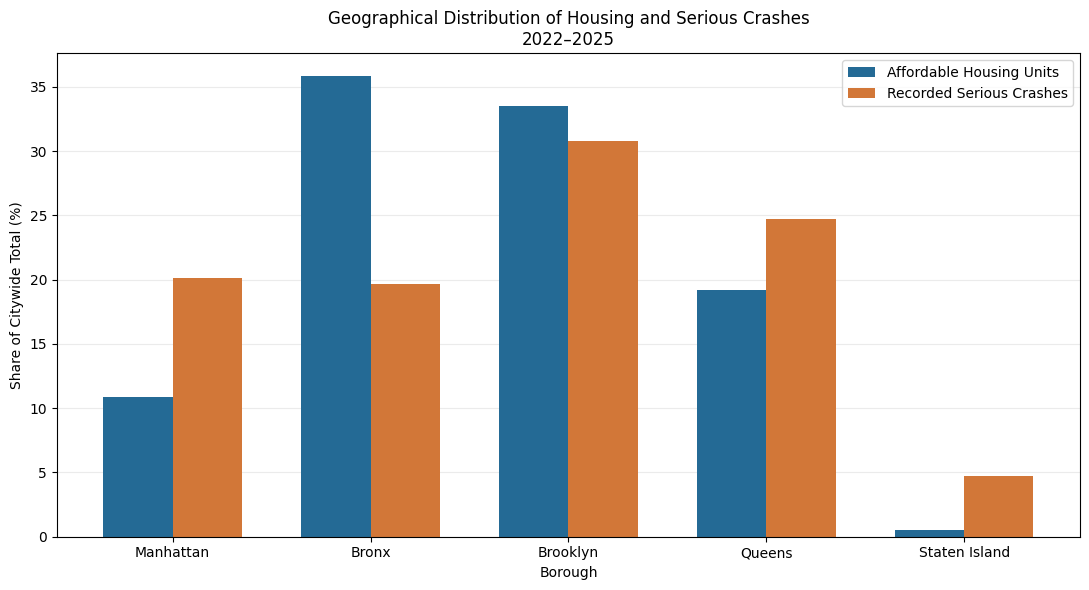

,housing_units,crashes,Housing Share (%),Crash Share (%)
borough,,,,
Manhattan,5205,1906,10.84,20.15
Bronx,17213,1857,35.84,19.63
Brooklyn,16115,2909,33.55,30.76
Queens,9235,2340,19.23,24.74
Staten Island,258,446,0.54,4.72


In [ ]:

# RQ1 — Borough distribution comparison

rq1 = (
    df.groupby("borough", as_index=False)
    .agg(
        housing_units=("housing_affordable_units", "sum"),
        crashes=("crash_events", "sum")
    )
)

assert rq1["housing_units"].sum() > 0
assert rq1["crashes"].sum() > 0

rq1["Housing Share (%)"] = (
    100 * rq1["housing_units"]
    / rq1["housing_units"].sum()
)

rq1["Crash Share (%)"] = (
    100 * rq1["crashes"]
    / rq1["crashes"].sum()
)

# Follow the original notebook's borough ordering
borough_order = [
    "Manhattan", "Bronx", "Brooklyn",
    "Queens", "Staten Island"
]

rq1 = rq1.set_index("borough").reindex(borough_order)

x = np.arange(len(rq1))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    rq1["Housing Share (%)"],
    width,
    label="Affordable Housing Units",
    color="#246a95"
)

ax.bar(
    x + width / 2,
    rq1["Crash Share (%)"],
    width,
    label="Recorded Serious Crashes",
    color="#d27738"
)

ax.set_xticks(x)
ax.set_xticklabels(borough_order)
ax.set_xlabel("Borough")
ax.set_ylabel("Share of Citywide Total (%)")
ax.set_title(
    "Geographical Distribution of Housing and Serious Crashes\n"
    "2022–2025"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

display(rq1.round(2))



### Average Affordable Housing Development Size and Crash Frequency

**Research Question:** Is the average number of affordable units per completed building associated with the frequency of reported serious traffic crashes?

**Objective:** Examine the relationship between the average counted affordable units per identified building and reported crash-event frequency across community district-years.

**Method:** Select observations with valid housing-unit totals and complete building identification. Divide counted affordable units by the number of identified buildings, then compare this measure against recorded crash events.

**Visualization:** Scatter plot with a linear trend line.

**Interpretation:** The chart describes an area-level association rather than an individual-building effect. Differences in geographic size and traffic activity may influence the observed relationship.


Eligible district-year observations: 60


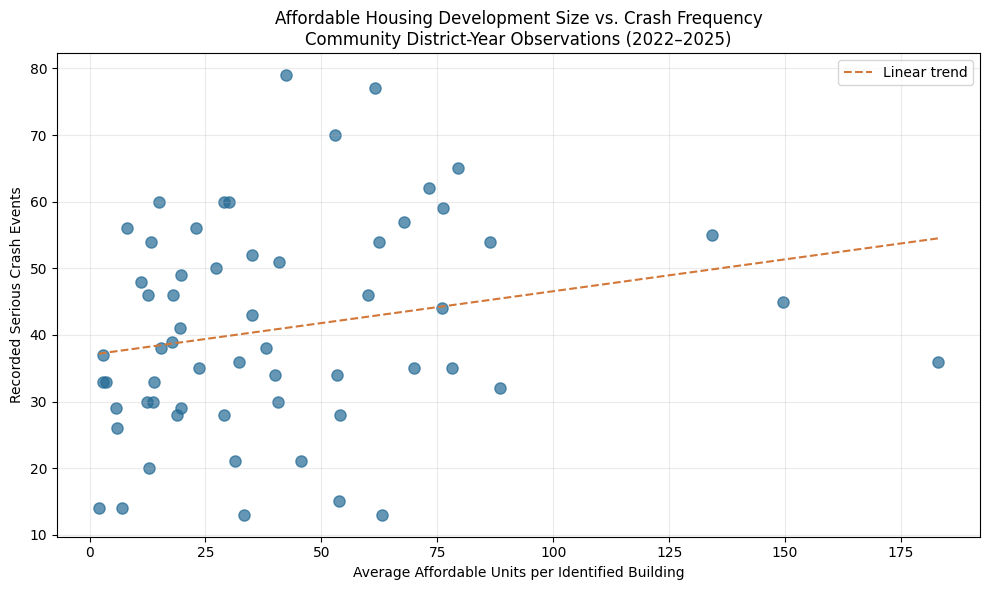

Pearson correlation: 0.218


,cd,borough,year,Units per Building,crash_events
1,101,Manhattan,2023,63.0,13
4,102,Manhattan,2022,23.5,35
8,103,Manhattan,2022,60.0,46
9,103,Manhattan,2023,18.0,46
17,105,Manhattan,2023,79.5,65
18,105,Manhattan,2024,35.0,52
20,106,Manhattan,2022,40.0,34
29,108,Manhattan,2023,35.0,43
40,111,Manhattan,2022,183.0,36
41,111,Manhattan,2023,12.5,46


In [ ]:

# RQ2 — Average affordable units per building

rq2 = df[
    (df["housing_identified_buildings"] > 0) &
    (df["housing_missing_building_id_records"] == 0) &
    (
        df["housing_affordable_units_known_records"]
        == df["housing_source_records"]
    )
].copy()

rq2["Units per Building"] = (
    rq2["housing_affordable_units"]
    / rq2["housing_identified_buildings"]
)

x = rq2["Units per Building"]
y = rq2["crash_events"]

print("Eligible district-year observations:", len(rq2))

if len(rq2) >= 3 and x.nunique() > 1 and y.nunique() > 1:

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.scatter(
        x, y,
        color="#246a95",
        s=65,
        alpha=0.7
    )

    # Linear trend for exploratory comparison
    slope, intercept = np.polyfit(x, y, 1)

    trend_x = np.linspace(x.min(), x.max(), 100)

    ax.plot(
        trend_x,
        slope * trend_x + intercept,
        linestyle="--",
        color="#d27738",
        label="Linear trend"
    )

    ax.set_xlabel("Average Affordable Units per Identified Building")
    ax.set_ylabel("Recorded Serious Crash Events")
    ax.set_title(
        "Affordable Housing Development Size vs. Crash Frequency\n"
        "Community District-Year Observations (2022–2025)"
    )

    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

    print("Pearson correlation:", round(x.corr(y), 3))

else:
    print("Insufficient variation for a meaningful scatter plot.")

display(
    rq2[[
        "cd", "borough", "year",
        "Units per Building", "crash_events"
    ]].head(10).round(2)
)



### Affordable Housing Proportion and Crash Frequency

**Research Question:** Does the proportion of affordable units within completed housing developments relate to the frequency of reported serious traffic crashes?

**Objective:** Investigate whether the share of counted affordable units within completed housing developments is associated with recorded crash frequency.

**Method:** Use the existing affordability-share measure calculated during dataset integration. Compare it with recorded crashes across eligible community district-years.

**Visualization:** Scatter plot.

**Interpretation:** The relationship is descriptive and does not measure individual residents' crash risk or imply a causal effect.


Eligible district-year observations: 218
Distinct affordability shares: 175


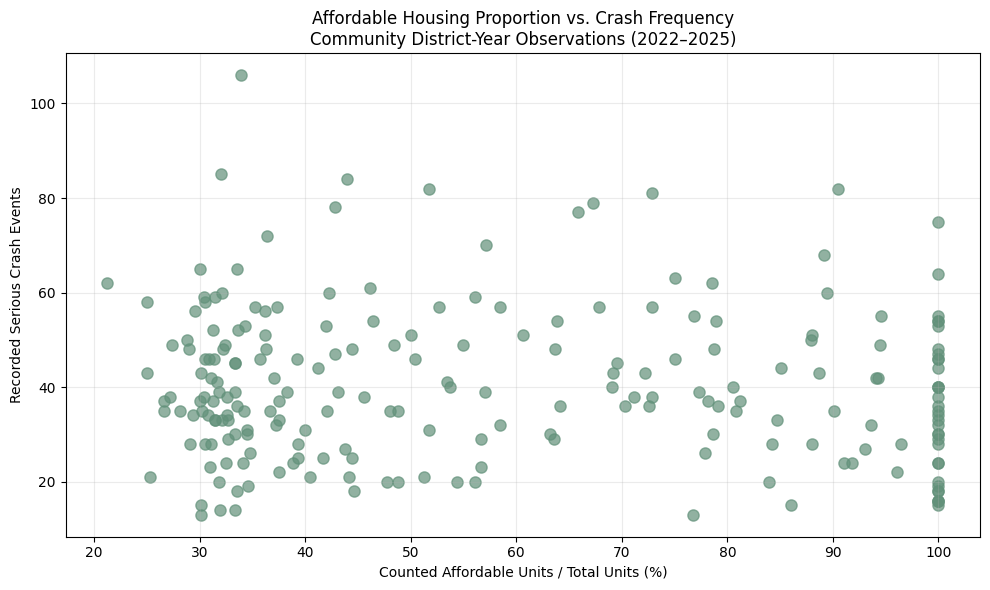

Pearson correlation: -0.064


,cd,borough,year,Affordable Share (%),crash_events
1,101,Manhattan,2023,30.14,13
4,102,Manhattan,2022,28.14,35
8,103,Manhattan,2022,75.00,46
9,103,Manhattan,2023,30.51,46
10,103,Manhattan,2024,53.70,40
11,103,Manhattan,2025,80.80,35
12,104,Manhattan,2022,21.26,62
13,104,Manhattan,2023,25.03,58
14,104,Manhattan,2024,27.19,38
15,104,Manhattan,2025,27.43,49


In [ ]:

# RQ3 — Affordable housing proportion

rq3 = df[
    (df["housing_source_records"] > 0) &
    df["housing_affordable_share_of_reported_total"].notna()
].copy()

rq3["Affordable Share (%)"] = (
    100 * rq3["housing_affordable_share_of_reported_total"]
)

# Validate the range
rq3 = rq3[
    rq3["Affordable Share (%)"].between(0, 100)
].copy()

x = rq3["Affordable Share (%)"]
y = rq3["crash_events"]

print("Eligible district-year observations:", len(rq3))
print("Distinct affordability shares:", x.nunique())

if len(rq3) >= 3 and x.nunique() > 1 and y.nunique() > 1:

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.scatter(
        x, y,
        color="#62917a",
        s=65,
        alpha=0.7
    )

    ax.set_title(
        "Affordable Housing Proportion vs. Crash Frequency\n"
        "Community District-Year Observations (2022–2025)"
    )
    ax.set_xlabel("Counted Affordable Units / Total Units (%)")
    ax.set_ylabel("Recorded Serious Crash Events")

    ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

    print("Pearson correlation:", round(x.corr(y), 3))

else:
    print("Insufficient variation for a meaningful relationship.")

display(
    rq3[[
        "cd", "borough", "year",
        "Affordable Share (%)", "crash_events"
    ]].head(10).round(2)
)



### Housing Activity Type and Crash Frequency

**Research Question:** Do areas dominated by new construction activity and areas dominated by housing preservation activity differ in their reported serious traffic crash frequency?

**Objective:** Compare recorded crash frequency between community district-years characterized by New Construction activity and those characterized by Preservation activity.

**Method:** Use the existing housing program activity summary. Classify each district-year according to which activity type has more housing source records, then match that classification with the existing district-year crash totals.

**Visualization:** Box plot.

**Interpretation:** Housing activity is measured using administrative project-start information, not physical construction commencement. Differences between categories are associations, not evidence that either activity type causes changes in traffic safety.


New Construction observations: 166
Preservation observations: 46


/tmp/ipykernel_1593/3452791830.py:96: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


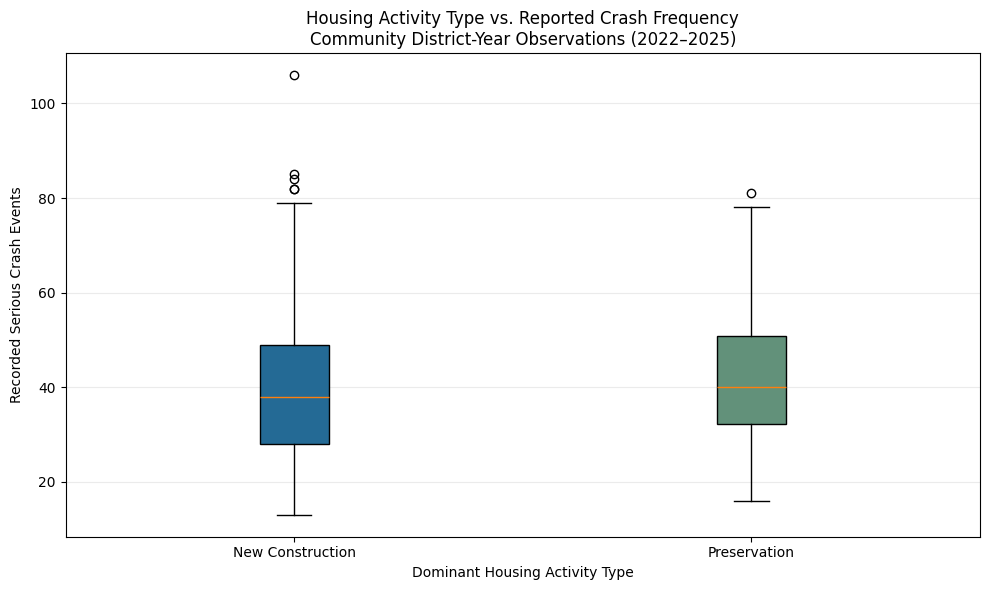

,count,mean,median
Dominant Type,,,
New Construction,166,40.19,38.0
Preservation,46,42.85,40.0


In [ ]:

# RQ4 — New Construction vs Preservation

activity = pd.DataFrame(ctx.activity).copy()

required_activity = [
    "cd", "project_start_year",
    "construction_type", "housing_source_records"
]

missing = [c for c in required_activity if c not in activity.columns]
if missing:
    raise KeyError(f"Missing activity columns: {missing}")

activity["cd"] = pd.to_numeric(activity["cd"], errors="raise")
activity["project_start_year"] = pd.to_numeric(
    activity["project_start_year"], errors="raise"
)
activity["housing_source_records"] = pd.to_numeric(
    activity["housing_source_records"], errors="raise"
)

activity = activity[
    activity["construction_type"].isin(
        ["New Construction", "Preservation"]
    )
].copy()

# Combine administrative activity across the other
# classification dimensions already present in ctx.activity
activity_summary = (
    activity.groupby(
        ["cd", "project_start_year", "construction_type"],
        as_index=False
    )["housing_source_records"].sum()
)

# Create one row per district-year
activity_wide = activity_summary.pivot_table(
    index=["cd", "project_start_year"],
    columns="construction_type",
    values="housing_source_records",
    aggfunc="sum",
    fill_value=0
).reset_index()

for col in ["New Construction", "Preservation"]:
    if col not in activity_wide.columns:
        activity_wide[col] = 0

activity_wide["Dominant Type"] = np.select(
    [
        activity_wide["New Construction"]
        > activity_wide["Preservation"],

        activity_wide["Preservation"]
        > activity_wide["New Construction"]
    ],
    [
        "New Construction",
        "Preservation"
    ],
    default="Equal"
)

# Both tables contain a unique district-year
rq4 = activity_wide.merge(
    df[["cd", "year", "crash_events"]],
    left_on=["cd", "project_start_year"],
    right_on=["cd", "year"],
    how="inner",
    validate="one_to_one"
)

# Exclude tied categories
rq4 = rq4[
    rq4["Dominant Type"] != "Equal"
].copy()

new = rq4.loc[
    rq4["Dominant Type"] == "New Construction",
    "crash_events"
]

preservation = rq4.loc[
    rq4["Dominant Type"] == "Preservation",
    "crash_events"
]

print("New Construction observations:", len(new))
print("Preservation observations:", len(preservation))

if len(new) > 0 and len(preservation) > 0:

    fig, ax = plt.subplots(figsize=(10, 6))

    box = ax.boxplot(
        [new, preservation],
        labels=["New Construction", "Preservation"],
        patch_artist=True
    )

    box["boxes"][0].set_facecolor("#246a95")
    box["boxes"][1].set_facecolor("#62917a")

    ax.set_title(
        "Housing Activity Type vs. Reported Crash Frequency\n"
        "Community District-Year Observations (2022–2025)"
    )
    ax.set_xlabel("Dominant Housing Activity Type")
    ax.set_ylabel("Recorded Serious Crash Events")

    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()

else:
    print("Insufficient observations for both activity types.")

display(
    rq4.groupby("Dominant Type")["crash_events"]
    .agg(["count", "mean", "median"])
    .round(2)
)
